# **<span style="color: #87CEEB;"> CS437/CS5317/EE414/EE513 Deep Learning Programming Assignment 3 Part-1A</span>**

# <span style="color: #9370DB;">**Submission Guidelines**</span>

- <span style="color: #9370DB;">Please rename the file to `<RollNumber>_PA3_1A
`.</span>
- <span style="color: #9370DB;">Please also submit a **.py** file of every Notebook. You can do this by exporting your **ipynb** to a Python script.</span>
- <span style="color: #9370DB;">Please submit a zipped folder of both your Jupyter Notebooks and Python script files.</span>




---

*italicized text*### Name:Sameer Rahil
### Roll Number: 27100162

<div style="width: 100%; text-align: center;">

<h1 style="color:rgb(244, 244, 245); font-size: 40px; font-weight: bold;">
    <span style="text-decoration-color: white;">THE LAST OF US:
    <span style="color:rgb(130, 89, 214);">DEEP LEARNING EDITION</span></span> 🎮
</h1>

<hr style="height: 10px; width: 100%; background-color: white; border: none; margin-top: 10px; margin-bottom: 10px;">
</div>



<img src="TLOU2.jpg" alt="The Last of Us" style="width: 100%; max-height: 500px; object-fit: cover;">


---

<p style="font-size: 18px;"> In the world of <b>The Last of Us</b>, society has collapsed due to the <b>Cordyceps Brain Infection (CBI)</b>, a fungal outbreak that transforms humans into aggressive, zombie-like creatures known as the <b>Infected</b>. Amidst this chaos, survivors navigate a perilous existence, facing threats from both the Infected and other human factions. </p> <p style="font-size: 18px;"> Our protagonist, <b>Ellie</b>, has endured unimaginable loss and hardship. After tragedy strikes her closest companions, she embarks on a relentless quest for justice. Her journey takes her across the desolate landscapes of a post-apocalyptic America, where she must confront both the horrors of the Infected and the ruthless factions vying for power. </p> <p style="font-size: 18px;"> Ellie's pursuit leads her to the ruins of <b>Hollywood</b>, a city once synonymous with glamour and fame, now a haunting wasteland overrun by the Infected. Intelligence suggests that members of the <b>Washington Liberation Front (WLF)</b> have infiltrated this area, disguising themselves among the hordes to evade detection. To achieve her goal, Ellie must distinguish friend from foe amidst the chaos. </p> <p style="font-size: 18px;"> In this dire scenario, Ellie turns to advanced technology for assistance. She discovers that, much like the Infected emit a distinct scent, humans possess unique facial features that can be analyzed to identify individuals. To leverage this, Ellie employs a <b>Variational Autoencoder (VAE)</b>, a deep learning model capable of learning and disentangling the underlying factors of facial images. By training the VAE on a dataset of celebrity faces, Ellie aims to develop a tool that can differentiate between the Infected, innocent survivors, and hidden WLF operatives. </p> <p style="font-size: 18px;"> This mission is not just about vengeance; it’s about survival, resilience, and the pursuit of justice in a world where morality is no longer black and white. With the VAE as her ally, Ellie embarks on a path fraught with danger, hope, and the unyielding human spirit's fight for redemption. </p>


<div style="width: 100%; text-align: center;">
<h1 style="color:rgb(244, 244, 245); font-size: 40px; font-weight: bold;">
    <span style="text-decoration-color: white;">Let's Start the:
    <span style="color:rgb(130, 89, 214);">Hunt</span></span> 🐾
</h1>
<hr style="height: 10px; width: 100%; background-color: white; border: none; margin-top: 10px; margin-bottom: 10px;">
</div>


# Here is Some Music to help you settle in for the Journey Ahead !

In [3]:
from IPython.display import Audio

# Replace 'your_audio_file.mp3' with your actual file name
audio_file = "03. The Last of Us.mp3"

# Display an audio player in the notebook
Audio(audio_file)


[audio player removed]

---

# <u>**Understanding Variational Autoencoders (VAEs)**</u>

## 📌 What is a Variational Autoencoder?
A **Variational Autoencoder (VAE)** is a **generative model** that learns to encode input data into a **latent space representation** and then reconstruct it back. Unlike traditional **Autoencoders**, VAEs introduce **probabilistic sampling** in the latent space, making them effective for generating new data and disentangling representations.

### 🔹 **Key Idea**
Instead of mapping an input $x$ to a fixed latent vector $z$, VAEs model the latent space as a **distribution**:

- **Encoder**: Learns a **mean** $\mu$ and **variance** $\sigma^2$ for each latent dimension.
- **Latent Space**: Instead of a fixed vector, we **sample** $z$ from a Gaussian distribution:
  
  $$
  z = \mu + \sigma \cdot \epsilon, \quad \epsilon \sim \mathcal{N}(0,1)
  $$

- **Decoder**: Takes the sampled $z$ and reconstructs the input image $\hat{x}$.

This allows for **smooth interpolations** and **better disentangled features** in the latent space.

---

## 📌 What is the **β-Hyperparameter**? 🛠️
The **β-VAE** (Beta Variational Autoencoder) introduces a **hyperparameter** $\beta$ in the loss function to **control the trade-off** between:

- **Reconstruction Quality** (How well the image is reconstructed).
- **Disentanglement** (How independent the latent factors are).

The modified **VAE loss function** becomes:

$$
\mathcal{L} = \mathbb{E}_{q(z|x)} [\log p(x|z)] - \beta D_{KL}(q(z|x) || p(z))
$$

Where:
- $\mathbb{E}_{q(z|x)} [\log p(x|z)]$ = **Reconstruction Loss** (Measures how well the output matches the input).
- $D_{KL}(q(z|x) || p(z))$ = **KL Divergence** (Forces latent space to follow a standard Gaussian distribution).
- $\beta$ = A scaling factor that controls the balance between reconstruction and disentanglement.

---

## 📌 **Why is KL Divergence Important?**
**Kullback-Leibler (KL) Divergence** measures how much one probability distribution **differs** from another. In VAEs, we use it to **regularize the latent space**, ensuring it follows a normal distribution.

### **🔹 General Formula for KL Divergence**
For any two probability distributions \( P(x) \) and \( Q(x) \), the KL Divergence is defined as:

$$
D_{KL}(P \parallel Q) = \sum_{x \in \mathcal{X}} P(x) \log \frac{P(x)}{Q(x)}
$$

This equation measures how much **information is lost** when \( Q(x) \) is used to approximate \( P(x) \). In simpler terms, it **penalizes deviations** from the target distribution.

### **🔹 KL Divergence in VAEs**
In **VAEs**, our encoder learns a latent representation \( q(z|x) \), which we want to keep **close to** a standard Gaussian prior \( p(z) \). Since both distributions are assumed to be **Gaussian**, we can derive a closed-form solution for KL Divergence:

$$
D_{KL}(q(z|x) \parallel p(z)) = \frac{1}{2} \sum_{i=1}^{d} \left( 1 + \log(\sigma_i^2) - \mu_i^2 - \sigma_i^2 \right)
$$

### **What do these terms represent?**
- **$\mu_i$**: The mean of the latent variable $z_i$.
- **$\sigma_i^2$**: The variance of the latent variable $z_i$.
- **$d$**: The dimensionality of the latent space.
- **$D_{KL}(q(z|x) || p(z))$**: Measures how much the learned latent space deviates from the assumed standard normal distribution.

### **Why do we need KL regularization?**
✅ It prevents **overfitting**.  
✅ It ensures **smooth latent representations**.  
✅ It allows for **better interpolation and sampling**.  

---


<!-- INSPIRATION PAPER HEADER -->
<div style="text-align: center;">
    <h2 style="color:rgb(248, 248, 244); font-size: 40px; font-weight: bold;">
        📜 <b>Inspiration for This Assignment</b>  
    </h2>
</div>

<!-- INSPIRATION PAPER BLOCK -->
<div style="padding: 25px; text-align: center; font-size: 22px; font-weight: bold; color:rgb(242, 244, 245);
            background: rgba(0, 0, 0, 0.6); border-radius: 15px; width: 70%; margin: auto;
            box-shadow: 0px 0px 30px rgba(213, 223, 16, 0.99);">
    
For this assignment, we will be taking **inspiration** from the following paper:  
📖 **[[Disentangled Representation Learning](https://arxiv.org/abs/2211.11695)]**  

Feel free to **read this for insights** and use it as a guide.  

</div>

<hr style="height: 10px; width: 80%; background: linear-gradient(to right, white, #FFD700, white); border: none; margin-top: 15px; margin-bottom: 15px;">

<!-- CHAPTER 1 HEADER -->
<div style="text-align: center;">
    <h1 style="color: #FF8C00; font-size: 55px; font-weight: bold;">
        🍁 <span style="color: white;">Chapter 1</span> -  
        <span style="color: #FFD700;">Fall</span> 🍂
        <span style="color: white;">[30 Points]</span>
    </h1>
    <hr style="height: 10px; width: 80%; background: linear-gradient(to right, white, #FF8C00, white); border: none; margin-top: 10px; margin-bottom: 10px;">
</div>

<!-- INTRODUCTION -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(255, 140, 0, 0.6);">
    
<b>The journey begins, not with a model, but with data.</b>  
This time, **you won’t be given a pre-processed dataset**—  
Instead, **you must take control.**  

In this part of the assignment, your task is to **load the raw CelebA dataset and preprocess it yourself.**  
This is an **essential skill** for anyone in this field:  

✅ **Identify, clean, and prepare data**  
✅ **Decide on preprocessing techniques**  
✅ **Gain full creative freedom** based on task requirements  

Your **dataset, your rules.**  
Your **pipeline, your approach.**  
**Let's begin.**  

</div>

<!-- WHAT IS CELEBA? -->
<div style="padding: 10px; text-align: center;">
    <h2 style="color: #FFD700; font-size: 35px; font-weight: bold;">
        🏷️ <b>What is the CelebA Dataset?</b>
    </h2>
</div>

<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(255, 140, 0, 0.6);">

CelebA (**Large-scale CelebFaces Attributes Dataset**) is one of the **most widely used datasets** in **computer vision & deep learning research**.  
It contains **202,599 images of celebrities** with **40 attribute labels** per image.  

💡 **Why is CelebA Important?**  
- It enables **facial attribute prediction** (e.g., age, gender, hair color, eyeglasses, etc.).  
- It allows experimentation with **variational autoencoders (VAEs)** for **feature disentanglement**.  
- It is **diverse**, containing **faces of different expressions, poses, and occlusions**.  

💾 **Dataset Structure:**  
📂 **img_align_celeba/** → The actual images (cropped & aligned)  
📄 **list_attr_celeba.txt** → Binary labels (1 or -1) for each image  
📄 **list_eval_partition.txt** → Specifies train/test/val splits  

**For this task, you will decide which files are needed based on your preprocessing choices.**  

</div>

<!-- TASK OVERVIEW HEADER -->
<div style="text-align: center;">
    <h2 style="color: #FFD700; font-size: 35px; font-weight: bold;">
        🎯 <b>Task Overview: Loading & Preprocessing CelebA</b>
    </h2>
</div>

<!-- TASK DETAILS -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(255, 140, 0, 0.6);">

📌 **Download the dataset** from this Link: ([CelebA Official Repository](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html)).  
💡 **Recommendation:** Use the **Aligned & Cropped Zip Folder**, but the choice is **yours**.  
📖 **Read the ReadMe File available in the dataset directory** to understand **what’s available**.  

### **🛠️ What You Need to Do:**
🔍 **Step 1:** Identify **which files** are necessary for your task. (Hint: You will need the Attributes, The Partitions and The Images themselves)
📥 **Step 2:** Download the required files from the link.  
📂 **Step 3:** Load the dataset into your notebook **(You are free to use ChatGPT, a custom loader, or any other method—Full Creative Freedom).**  
🖼️ **Step 4:** Display **5 random samples** from the **train** split & **5 random samples** from the **test** split.  
📑 **Step 5:** **Examples of what your visualizations should look like are in the FAQs document.**  

⚠️ **IMPORTANT:** The CelebA dataset is **too large** to be used in its entirety.  
🚀 **We strongly recommend reducing it to a subset of 50,000 images** (80-20 split for Train/Eval).  
- **This will significantly reduce training time.**  
- **With 50,000 images, training will take ~40 minutes (CPU) on all β-values.**  
- **Ignoring this will slow down your progress!**  

</div>

<!-- FINAL GRADING WARNING -->
<div style="padding: 30px; text-align: center; font-size: 22px; font-weight: bold; color: red;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px; width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(255, 0, 0, 0.6);">

⚠️ **Your marks for this task depend entirely on your success in loading and visualizing the dataset.**  
If done incorrectly, you **might not be able to complete the rest of the tasks.**  

</div>


In [4]:
# Code Here
from google.colab import drive
drive.mount('/content/drive')
import os
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
project_dir="/content/drive/MyDrive/27100162_PA3_1A&1B"
attr_path=os.path.join(project_dir,"list_attr_celeba.txt")
partition_path=os.path.join(project_dir,"list_eval_partition.txt")
zip_path=os.path.join(project_dir,"img_align_celeba.zip")
extract_dir="/content"
img_dir="/content/img_align_celeba"
if not os.path.exists(img_dir):
    with zipfile.ZipFile(zip_path,"r") as zip_ref:
        zip_ref.extractall(extract_dir)
random.seed(27100162)
np.random.seed(27100162)

Mounted at /content/drive


In [5]:
# Code Here
with open(attr_path,"r") as f:
    total_images=int(f.readline().strip())
    attr_names=f.readline().strip().split()
attr_df=pd.read_csv(attr_path,sep=r"\s+",skiprows=2,header=None)
attr_df.columns=["image_id"]+attr_names
partition_df=pd.read_csv(partition_path,sep=r"\s+",header=None,names=["image_id","partition"])
df=attr_df.merge(partition_df,on="image_id")
train_df=df[df["partition"]==0].sample(n=40000,random_state=42).reset_index(drop=True)
test_df=df[df["partition"]==2].sample(n=10000,random_state=42).reset_index(drop=True)
print(total_images)
print(train_df.shape)
print(test_df.shape)

202599
(40000, 42)
(10000, 42)


In [6]:
# Code Here
import torch
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms
transform=transforms.Compose([transforms.Resize((64,64)),transforms.ToTensor()])
class CelebADataset(Dataset):
    def __init__(self,dataframe,img_dir,transform=None):
        self.dataframe=dataframe.reset_index(drop=True)
        self.img_dir=img_dir
        self.transform=transform
    def __len__(self):
        return len(self.dataframe)
    def __getitem__(self,idx):
        image_id=self.dataframe.loc[idx,"image_id"]
        image=Image.open(os.path.join(self.img_dir,image_id)).convert("RGB")
        if self.transform:
            image=self.transform(image)
        attrs=torch.tensor(self.dataframe.iloc[idx,1:-1].astype(np.float32).values)
        return image,attrs,image_id
train_dataset=CelebADataset(train_df,img_dir,transform)
test_dataset=CelebADataset(test_df,img_dir,transform)
train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True,num_workers=0,pin_memory=True)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=False,num_workers=0,pin_memory=True)
print(len(train_dataset))
print(len(test_dataset))

40000
10000


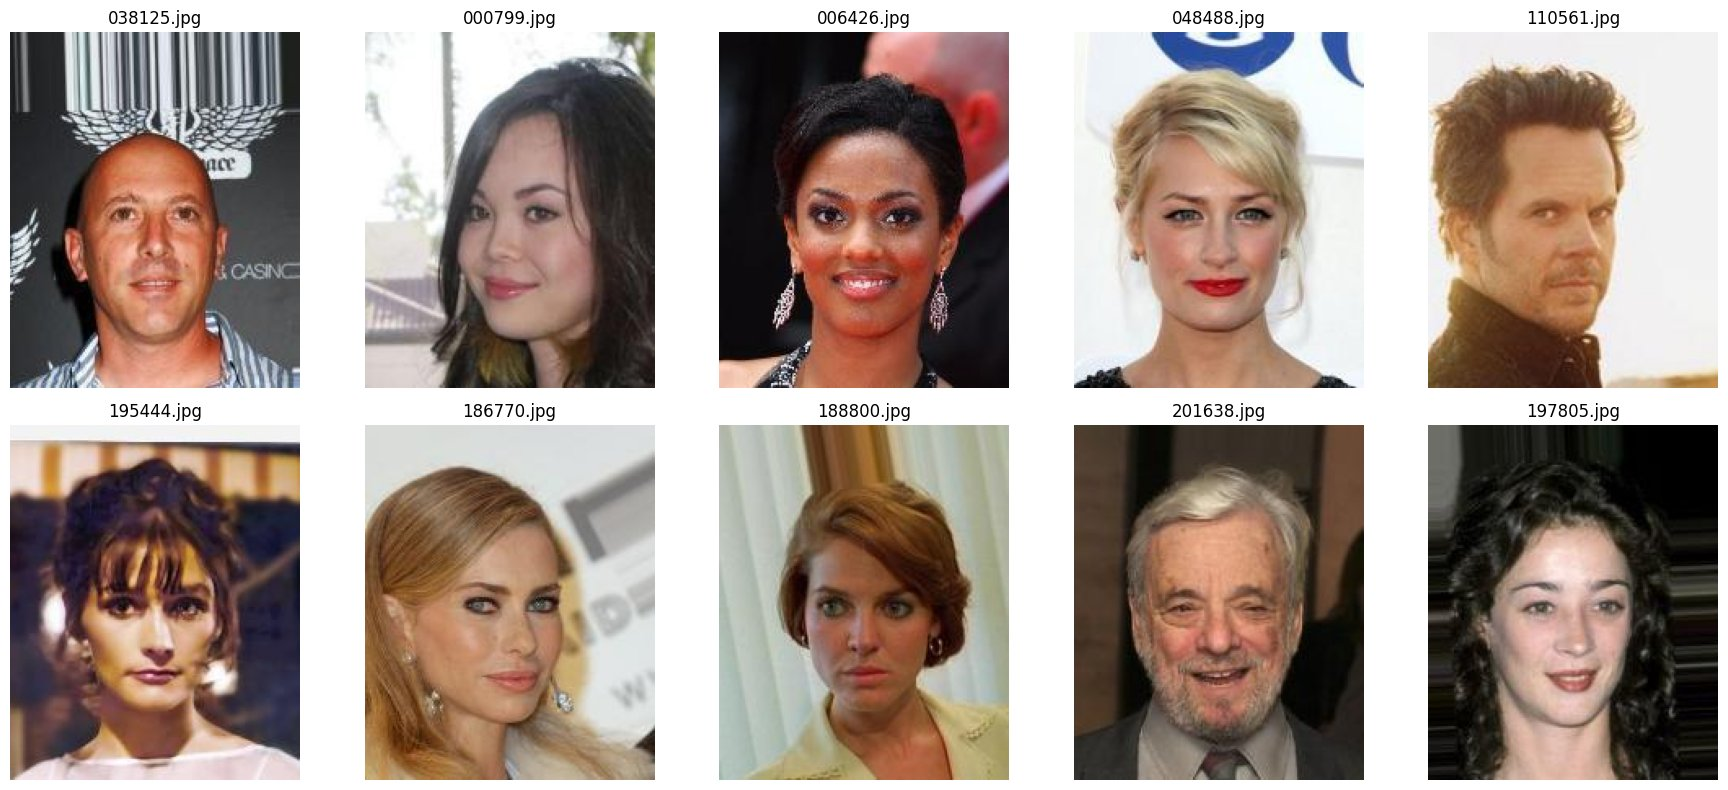

In [7]:
# Code Here
train_samples=train_df.sample(n=5).reset_index(drop=True)
test_samples=test_df.sample(n=5).reset_index(drop=True)
fig,axes=plt.subplots(2,5,figsize=(18,8))
for i in range(5):
    train_img=Image.open(os.path.join(img_dir,train_samples.loc[i,"image_id"])).convert("RGB")
    axes[0,i].imshow(train_img)
    axes[0,i].set_title(train_samples.loc[i,"image_id"])
    axes[0,i].axis("off")
for i in range(5):
    test_img=Image.open(os.path.join(img_dir,test_samples.loc[i,"image_id"])).convert("RGB")
    axes[1,i].imshow(test_img)
    axes[1,i].set_title(test_samples.loc[i,"image_id"])
    axes[1,i].axis("off")
axes[0,0].set_ylabel("Train",fontsize=14)
axes[1,0].set_ylabel("Test",fontsize=14)
plt.tight_layout()
plt.show()

<div style="text-align: center;">
    <h1 style="color: rgb(255, 183, 76); font-size: 50px; font-weight: bold;">
        ☀️ <span style="color: white;">Chapter 2</span> -  
        <span style="color: rgb(255, 183, 76);">Summer</span> ☀️
        <span style="color: white;">[30 Points]</span>
    </h1>
    <hr style="height: 8px; width: 80%; background: linear-gradient(to right, white, rgb(255, 183, 76), white); border: none; margin-top: 10px; margin-bottom: 10px;">
</div>


<!-- MISSION HEADER -->
<div style="text-align: center;">
    <h1 style="color: #FFA500; font-size: 55px; font-weight: bold;">
        💻 <span style="color: white;">TIME TO START CODING!</span> 💻
    </h1>
</div>

<!-- CINEMATIC INTRO -->
<div style="padding: 25px; text-align: center; font-size: 24px; font-style: italic; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px; width: 70%; margin: auto;
            box-shadow: 0px 0px 30px rgba(255, 165, 0, 0.6);">
    
"This is where the real challenge begins..."  
Ellie’s journey led her here. **Your journey begins now.**

</div>

<hr style="height: 8px; width: 80%; background: linear-gradient(to right, white, #FFA500, white); border: none; margin-top: 15px; margin-bottom: 15px;">

<!-- MISSION OBJECTIVE TITLE -->
<div style="text-align: center;">
    <h2 style="color: rgb(255, 183, 76); font-size: 35px; font-weight: bold;">
        🎯 <b>Mission Objective:</b> Train a <b>β-VAE</b> to Disentangle Features and Uncover the WLF Operatives
    </h2>
</div>

<!-- STORY-THEMED CODING CHALLENGE -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(255, 165, 0, 0.6);">

The **data is ready**, the **tools are set**, and now it’s time to **dive into the unknown**.  
Just like **Ellie**, you must **navigate through uncertainty**,  
experiment with different **β-values**, and **uncover the hidden representations** within faces.

</div>

<!-- FINAL CALL TO ACTION -->
<div style="padding: 20px; text-align: center; font-size: 22px; font-weight: bold; color: rgb(255, 183, 76);">
    You are on your own from this point onwards.  
    <br> <b>Good luck, survivor.</b> 🏹🔥
</div>


## **🔹 Your Task: Complete the β-VAE Implementation**

### **📌 Key Components to Consider**
1. **Encoder (`encode` function)**
   - Takes an input image .
   - Passes it thorugh **Convolution Layers**
   - Outputs two vectors:
     - **Mean (μ):** The predicted mean of the latent distribution.
     - **Log variance (logσ²):** The predicted variance (log-scale) of the latent distribution.

1. **Reparameterization Trick (`reparameterize` function)**
   - Uses the **mean (μ) and log variance (logσ²)** to create a latent vector **z**.
   - Adds **random noise** to make the model **stochastic**.

2. **Decoder (`decode` function)**
   - Takes a latent vector **z**.
   - Passes it through **transposed convolution layers** to reconstruct the image.

3. **Forward Pass (`forward` function)**
   - Takes an input image.
   - **Encodes → Reparameterizes → Decodes** it.
   - Returns **the reconstructed image, mean, and log variance**.

`Note:`: You do not neccseccarily need to follow the structure above , you are free to make whatever functions you require , change constructors values, Adjust Hyperparameters, GO CRAZY (Clicker Symptoms Starting to show xD).Please also look into how different 'latent_dim' values effect your results and why? Currently a default value of 10 is set



# B-VAE Architecture

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class BetaVAE(nn.Module):
    def __init__(self, latent_dim=10, beta=1.0):
        """
        Beta-VAE Model

        Args:
            latent_dim (int): Dimension of the latent space (default = 10)
            beta (float): Weighting factor for KL divergence in loss function
        """
        super(BetaVAE, self).__init__()
        self.beta = beta  # Hyperparameter for disentanglement
        self.latent_dim = latent_dim

        # 🚀 Define the encoder, decoder, and other layers here
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True)
        )
        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)
        self.decoder_input = nn.Linear(latent_dim, 256 * 4 * 4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def encode(self, x):
        """
        Encode input image to latent space representations (μ, logσ²).
        """
        h = self.encoder(x)
        h = h.view(h.size(0), -1)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar
        #pass  # 🚀 Implement this function

    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick to sample latent vector z from μ and logσ².
        """
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
        #pass  # 🚀 Implement this function

    def decode(self, z):
        """
        Decode latent vector z back to image space.
        """
        h = self.decoder_input(z)
        h = h.view(-1, 256, 4, 4)
        return self.decoder(h)
        #pass  # 🚀 Implement this function

    def forward(self, x):
        """
        Full forward pass: Encode → Reparameterize → Decode
        """
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar
        #pass  # 🚀 Implement this function


# B-VAE Loss

In [9]:

def beta_vae_loss(recon_x, x, mu, logvar, beta=1.0):
    """
    Beta-VAE Loss Function

    Args:
        recon_x: Reconstructed image
        x: Original image
        mu: Mean of latent distribution
        logvar: Log variance of latent distribution
        beta: KL divergence weighting factor

    Returns:
        Total loss
    """
    # 🚀 Compute Reconstruction Loss (Mean Squared Error)
    recon_loss = F.mse_loss(recon_x, x, reduction="sum")

    # 🚀 Compute KL Divergence Loss
    kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    # 🚀 Compute Total Loss
    total_loss = recon_loss + beta * kld_loss

    return total_loss

# 📌 Training Instructions
Now that you have implemented the Beta-VAE, it's time to train it on the CelebA dataset.
### 🎯 Your Tasks
- ✅ Train the Beta-VAE with at least 4 different β values (1, 5, 10, 50).
- ✅ Train for a minimum of 3 epochs (you can train for more).
- ✅ Log and analyze how different β values affect:
- Pleas use `tqdm` library to track progress as it can take up to `45 mins of training` on a CPU

In [10]:
# Training

# 🚀 1. Define Hyperparameters
# 🚀 2. Initialize Model & Optimizer
# 🚀 3. Define Training Function
# 🚀 4. Define Validation Function
# 🚀 5. Train Model for Each β Value
# 🚀 6. Save the Trained Model
from tqdm.auto import tqdm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FIXED_BETA = 5
CH2_LATENT_DIMS = [5, 10, 15]
CH2_EPOCHS = 3
CH2_DEFAULT_NUM_SAMPLES = 10
CH2_DEFAULT_VARIATION_RANGE = (-3, 3)
BETA_VALUES = [1, 5, 10, 50]
EPOCHS = 3
LEARNING_RATE = 1e-3
SAVE_DIR = os.path.join(project_dir, "saved_models")
os.makedirs(SAVE_DIR, exist_ok=True)
chapter2_models = {}
chapter2_history = {}
chapter2_results = []
trained_models = {}
training_history = {}
results = []

def train_epoch(model, dataloader, optimizer):
    model.train()
    running_total = 0.0
    running_kld = 0.0
    running_recon = 0.0
    progress_bar = tqdm(dataloader, leave=False)
    for images, _, _ in progress_bar:
        images = images.to(device)
        optimizer.zero_grad()
        recon_x, mu, logvar = model(images)
        loss = beta_vae_loss(recon_x, images, mu, logvar, beta=model.beta)
        recon_loss = F.mse_loss(recon_x, images, reduction="sum")
        kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        loss.backward()
        optimizer.step()
        running_total += loss.item()
        running_kld += kld_loss.item()
        running_recon += recon_loss.item()
        progress_bar.set_description(f"beta={model.beta} train")
    dataset_size = len(dataloader.dataset)
    return running_total / dataset_size, running_kld / dataset_size, running_recon / dataset_size

def validate_epoch(model, dataloader):
    model.eval()
    running_total = 0.0
    running_kld = 0.0
    running_recon = 0.0
    progress_bar = tqdm(dataloader, leave=False)
    with torch.no_grad():
        for images, _, _ in progress_bar:
            images = images.to(device)
            recon_x, mu, logvar = model(images)
            loss = beta_vae_loss(recon_x, images, mu, logvar, beta=model.beta)
            recon_loss = F.mse_loss(recon_x, images, reduction="sum")
            kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
            running_total += loss.item()
            running_kld += kld_loss.item()
            running_recon += recon_loss.item()
            progress_bar.set_description(f"beta={model.beta} val")
    dataset_size = len(dataloader.dataset)
    return running_total / dataset_size, running_kld / dataset_size, running_recon / dataset_size

for latent_dim in CH2_LATENT_DIMS:
    model = BetaVAE(latent_dim=latent_dim, beta=FIXED_BETA).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    for epoch in range(CH2_EPOCHS):
        train_total, train_kld, train_recon = train_epoch(model, train_loader, optimizer)
        val_total, val_kld, val_recon = validate_epoch(model, test_loader)
        history.append({
            "epoch": epoch + 1,
            "train_total_loss": train_total,
            "train_kl_divergence": train_kld,
            "train_reconstruction_loss": train_recon,
            "val_total_loss": val_total,
            "val_kl_divergence": val_kld,
            "val_reconstruction_loss": val_recon
        })
        print(f"Chapter 2 | Beta={FIXED_BETA} | Latent Dim={latent_dim} | Epoch {epoch+1}/{CH2_EPOCHS} | Train Total Loss={train_total:.4f} | Train KL Divergence={train_kld:.4f} | Train Reconstruction Loss={train_recon:.4f} | Val Total Loss={val_total:.4f} | Val KL Divergence={val_kld:.4f} | Val Reconstruction Loss={val_recon:.4f}")
    torch.save({
        "model_state_dict": model.state_dict(),
        "beta": FIXED_BETA,
        "latent_dim": latent_dim
    }, os.path.join(SAVE_DIR, f"chapter2_beta_{FIXED_BETA}_latent_{latent_dim}.pth"))
    chapter2_models[latent_dim] = model
    chapter2_history[latent_dim] = history
    chapter2_results.append({
        "Latent Dim": latent_dim,
        "Beta Value": FIXED_BETA,
        "Total Loss": round(history[-1]["val_total_loss"], 4),
        "KL Divergence": round(history[-1]["val_kl_divergence"], 4),
        "Reconstruction Loss": round(history[-1]["val_reconstruction_loss"], 4)
    })

chapter2_results_df = pd.DataFrame(chapter2_results)
BEST_LATENT_DIM = int(chapter2_results_df.sort_values("Total Loss").iloc[0]["Latent Dim"])
LATENT_DIM = BEST_LATENT_DIM
print("Best latent dim selected from Chapter 2:", BEST_LATENT_DIM)

for beta in BETA_VALUES:
    model = BetaVAE(latent_dim=LATENT_DIM, beta=beta).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    for epoch in range(EPOCHS):
        train_total, train_kld, train_recon = train_epoch(model, train_loader, optimizer)
        val_total, val_kld, val_recon = validate_epoch(model, test_loader)
        history.append({
            "epoch": epoch + 1,
            "train_total_loss": train_total,
            "train_kl_divergence": train_kld,
            "train_reconstruction_loss": train_recon,
            "val_total_loss": val_total,
            "val_kl_divergence": val_kld,
            "val_reconstruction_loss": val_recon
        })
        print(f"Chapter 3 | Beta={beta} | Latent Dim={LATENT_DIM} | Epoch {epoch+1}/{EPOCHS} | Train Total Loss={train_total:.4f} | Train KL Divergence={train_kld:.4f} | Train Reconstruction Loss={train_recon:.4f} | Val Total Loss={val_total:.4f} | Val KL Divergence={val_kld:.4f} | Val Reconstruction Loss={val_recon:.4f}")
    torch.save({
        "model_state_dict": model.state_dict(),
        "beta": beta,
        "latent_dim": LATENT_DIM
    }, os.path.join(SAVE_DIR, f"beta_vae_beta_{beta}.pth"))
    trained_models[beta] = model
    training_history[beta] = history
    results.append({
        "Beta Value": beta,
        "Latent Dim": LATENT_DIM,
        "Total Loss": round(history[-1]["val_total_loss"], 4),
        "KL Divergence": round(history[-1]["val_kl_divergence"], 4),
        "Reconstruction Loss": round(history[-1]["val_reconstruction_loss"], 4)
    })

results_df = pd.DataFrame(results)
chapter2_results_df

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Chapter 2 | Beta=5 | Latent Dim=5 | Epoch 1/3 | Train Total Loss=485.9462 | Train KL Divergence=8.4907 | Train Reconstruction Loss=443.4929 | Val Total Loss=438.6964 | Val KL Divergence=9.4733 | Val Reconstruction Loss=391.3297


  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Chapter 2 | Beta=5 | Latent Dim=5 | Epoch 2/3 | Train Total Loss=437.0041 | Train KL Divergence=9.0839 | Train Reconstruction Loss=391.5845 | Val Total Loss=432.1610 | Val KL Divergence=8.8889 | Val Reconstruction Loss=387.7165


... (54 outputs left out)

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Chapter 3 | Beta=50 | Latent Dim=15 | Epoch 3/3 | Train Total Loss=656.3378 | Train KL Divergence=2.7430 | Train Reconstruction Loss=519.1867 | Val Total Loss=654.2010 | Val KL Divergence=2.9329 | Val Reconstruction Loss=507.5577


,Latent Dim,Beta Value,Total Loss,KL Divergence,Reconstruction Loss
0,5,5,429.5867,9.3352,382.9106
1,10,5,373.1218,13.4431,305.9065
2,15,5,355.3273,17.4520,268.0675


## 📊 **Logging Your Results**

Once you have trained your **β-VAE** model with different β values, log your results in a table format like the one below.

|   **Beta Value** |   **Total Loss** |   **KL Divergence** |   **Reconstruction Loss** |
|:--------------:|:-------------:|:----------------:|:----------------------:|
| 1  | 1189.31 | 32.7504 | 1156.56 |
| 5  | 1261.73 | 22.6921 | 1148.27 |
| 10 | 1330.06 | 18.7226 | 1142.84 |
| 50 | 1837.18 | 10.5795 | 1308.21 |

### 📌 **How to Interpret Your Table**
- **Total Loss**: The overall loss for the VAE combining both **reconstruction loss** and **KL divergence**.
- **KL Divergence**: How much the learned latent space deviates from a normal Gaussian distribution.
- **Reconstruction Loss**: Measures how well the model reconstructs the input images.

📢 **Your task is to analyze how the KL Divergence and Reconstruction Loss change as β increases!**


In [11]:
## log Your Own results in the same way as shown above
#ok

#did above btw since not specified anyways

### 🧩 **Visualizing Disentangled Latent Factors**  

Now that you have trained your **β-VAE**, it's time to **explore the latent space** and visualize how different latent factors influence image generation!  

### 🔍 **What You Need to Do:**  
1️⃣ **Select a Base Latent Vector**:  
   - Start with a vector **initialized to zeros** (or another meaningful initialization).  
   - This represents the "average" or neutral latent space representation.  

2️⃣ **Vary One Latent Dimension at a Time**:  
   - Change the value of **one latent dimension** while keeping all others fixed.  
   - Observe how this affects the generated images.  

3️⃣ **Generate Multiple Samples**:  
   - Choose a **suitable range** for variation (e.g., **between -3 and 3**).  
   - Sample **at least 10 variations** across this range.  

4️⃣ **Plot the Results in a Grid**:  
   - Each **row** should represent a different latent dimension.  
   - Each **column** should represent a different sampled value within the chosen range.  
   - Label the axes appropriately for interpretation.  

### 🎯 **Goal:**  
Your goal is to **interpret how different latent dimensions affect image generation**.  
- Do some dimensions **control specific attributes** (e.g., smiling, hair color, face shape)?  
- Are some dimensions **more interpretable** than others?  
- Does increasing β make disentanglement clearer?  

📝 **Experiment with different variation ranges and observe how your β-VAE captures meaningful factors of variation!**  

🔥 **Time to unlock the secrets of the latent space!** 🚀


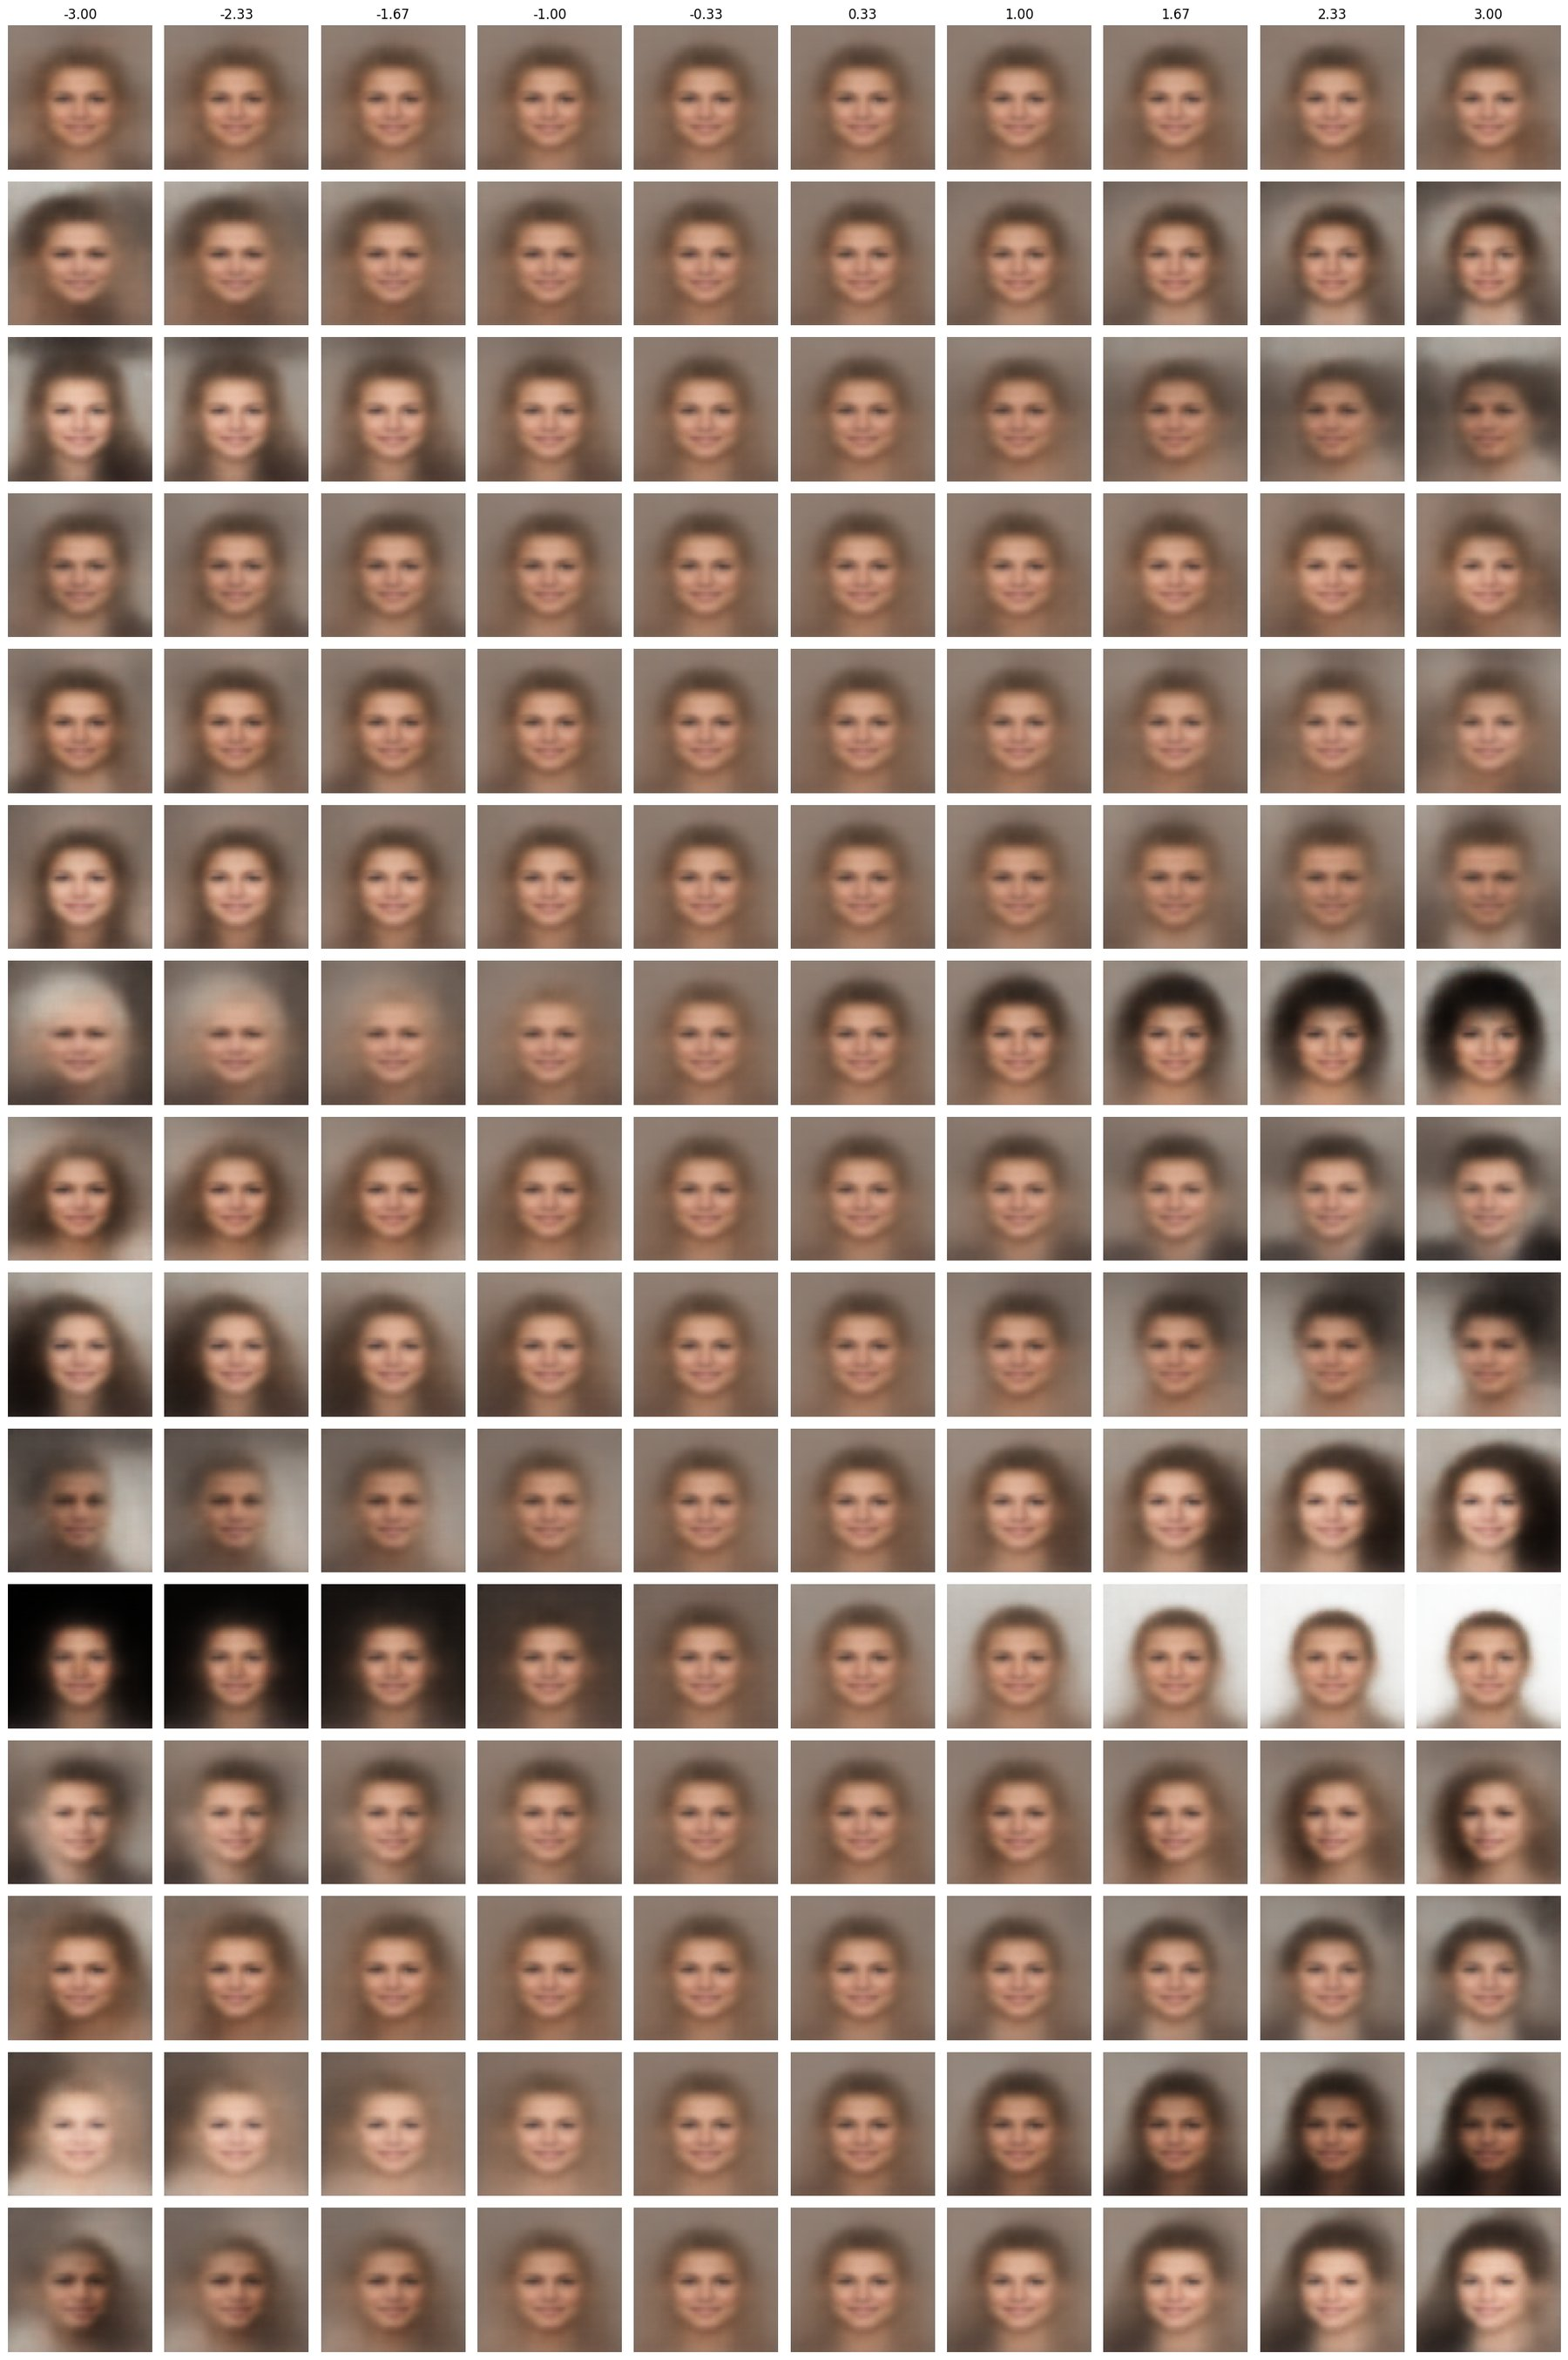

In [12]:
def visualize_disentangled_latent_factors(model, latent_dim, num_samples=10, variation_range=(-3, 3)):
    """
    Visualize disentangled latent factors by varying one latent dimension.

    Parameters:
    - model: Trained β-VAE model.
    - latent_dim: Number of latent dimensions in the model.
    - num_samples: Number of samples to generate per latent dimension.
    - variation_range: Range of values to vary for each latent dimension.
    """
    model.eval()

    #--------------------------------------------------------------------------------------------------------
    # CODE HERE
    values = torch.linspace(variation_range[0], variation_range[1], num_samples)
    model_device = next(model.parameters()).device
    fig, axes = plt.subplots(latent_dim, num_samples, figsize=(num_samples * 2, latent_dim * 2))
    if latent_dim == 1:
        axes = np.expand_dims(axes, axis=0)
    with torch.no_grad():
        for i in range(latent_dim):
            for j, value in enumerate(values):
                z = torch.zeros(1, latent_dim, device=model_device)
                z[0, i] = value
                generated = model.decode(z).squeeze(0).permute(1, 2, 0).cpu().numpy()
                axes[i, j].imshow(np.clip(generated, 0, 1))
                axes[i, j].axis("off")
                if i == 0:
                    axes[i, j].set_title(f"{value.item():.2f}")
                if j == 0:
                    axes[i, j].set_ylabel(f"z{i+1}")

    plt.tight_layout()
    plt.show()
    return

    #--------------------------------------------------------------------------------------------------------

    #NotImplementedError("Visualize disentangled latent factors by varying one latent dimension.")

# Parameters
latent_dim = LATENT_DIM # As per your model
num_samples =10# Number of variations per latent dimension
variation_range =(-3, 3) # Adjust this range if needed i.e (-3,3)

# Visualize disentangled latent factors
visualize_disentangled_latent_factors(trained_models[10], latent_dim=latent_dim, num_samples=num_samples, variation_range=variation_range)


Chapter 2 | Beta = 5 | Latent Dim = 5 | Num Samples = 10 | Variation Range = (-3, 3)


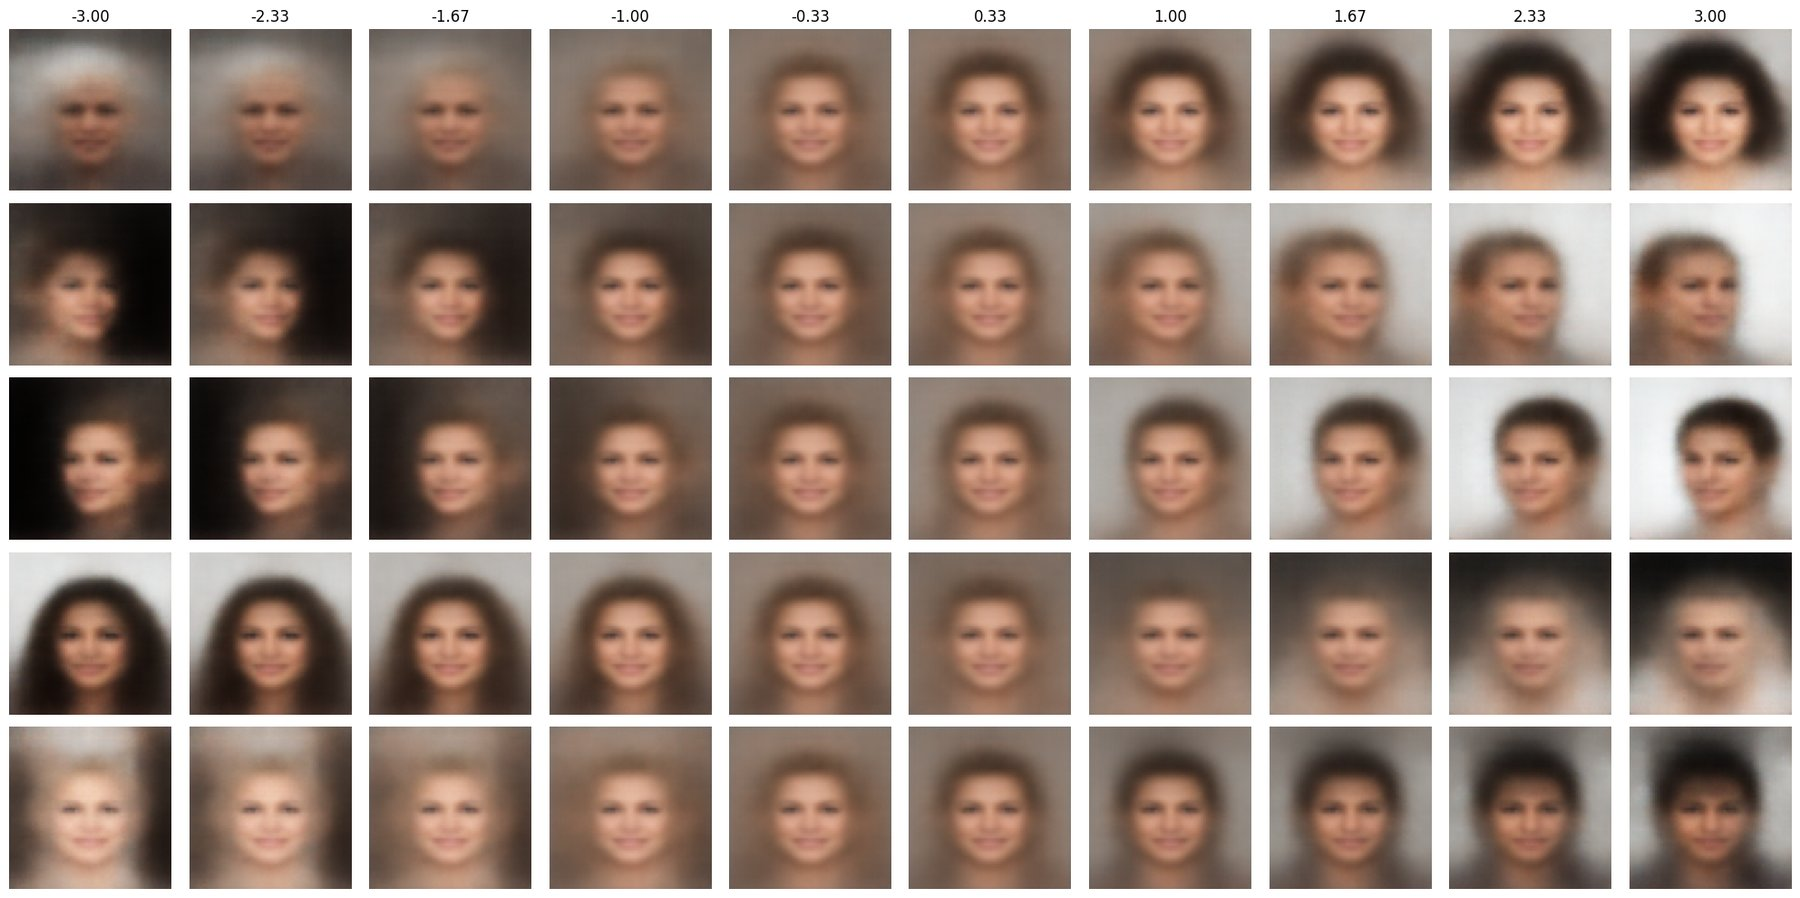

Chapter 2 | Beta = 5 | Latent Dim = 10 | Num Samples = 10 | Variation Range = (-3, 3)


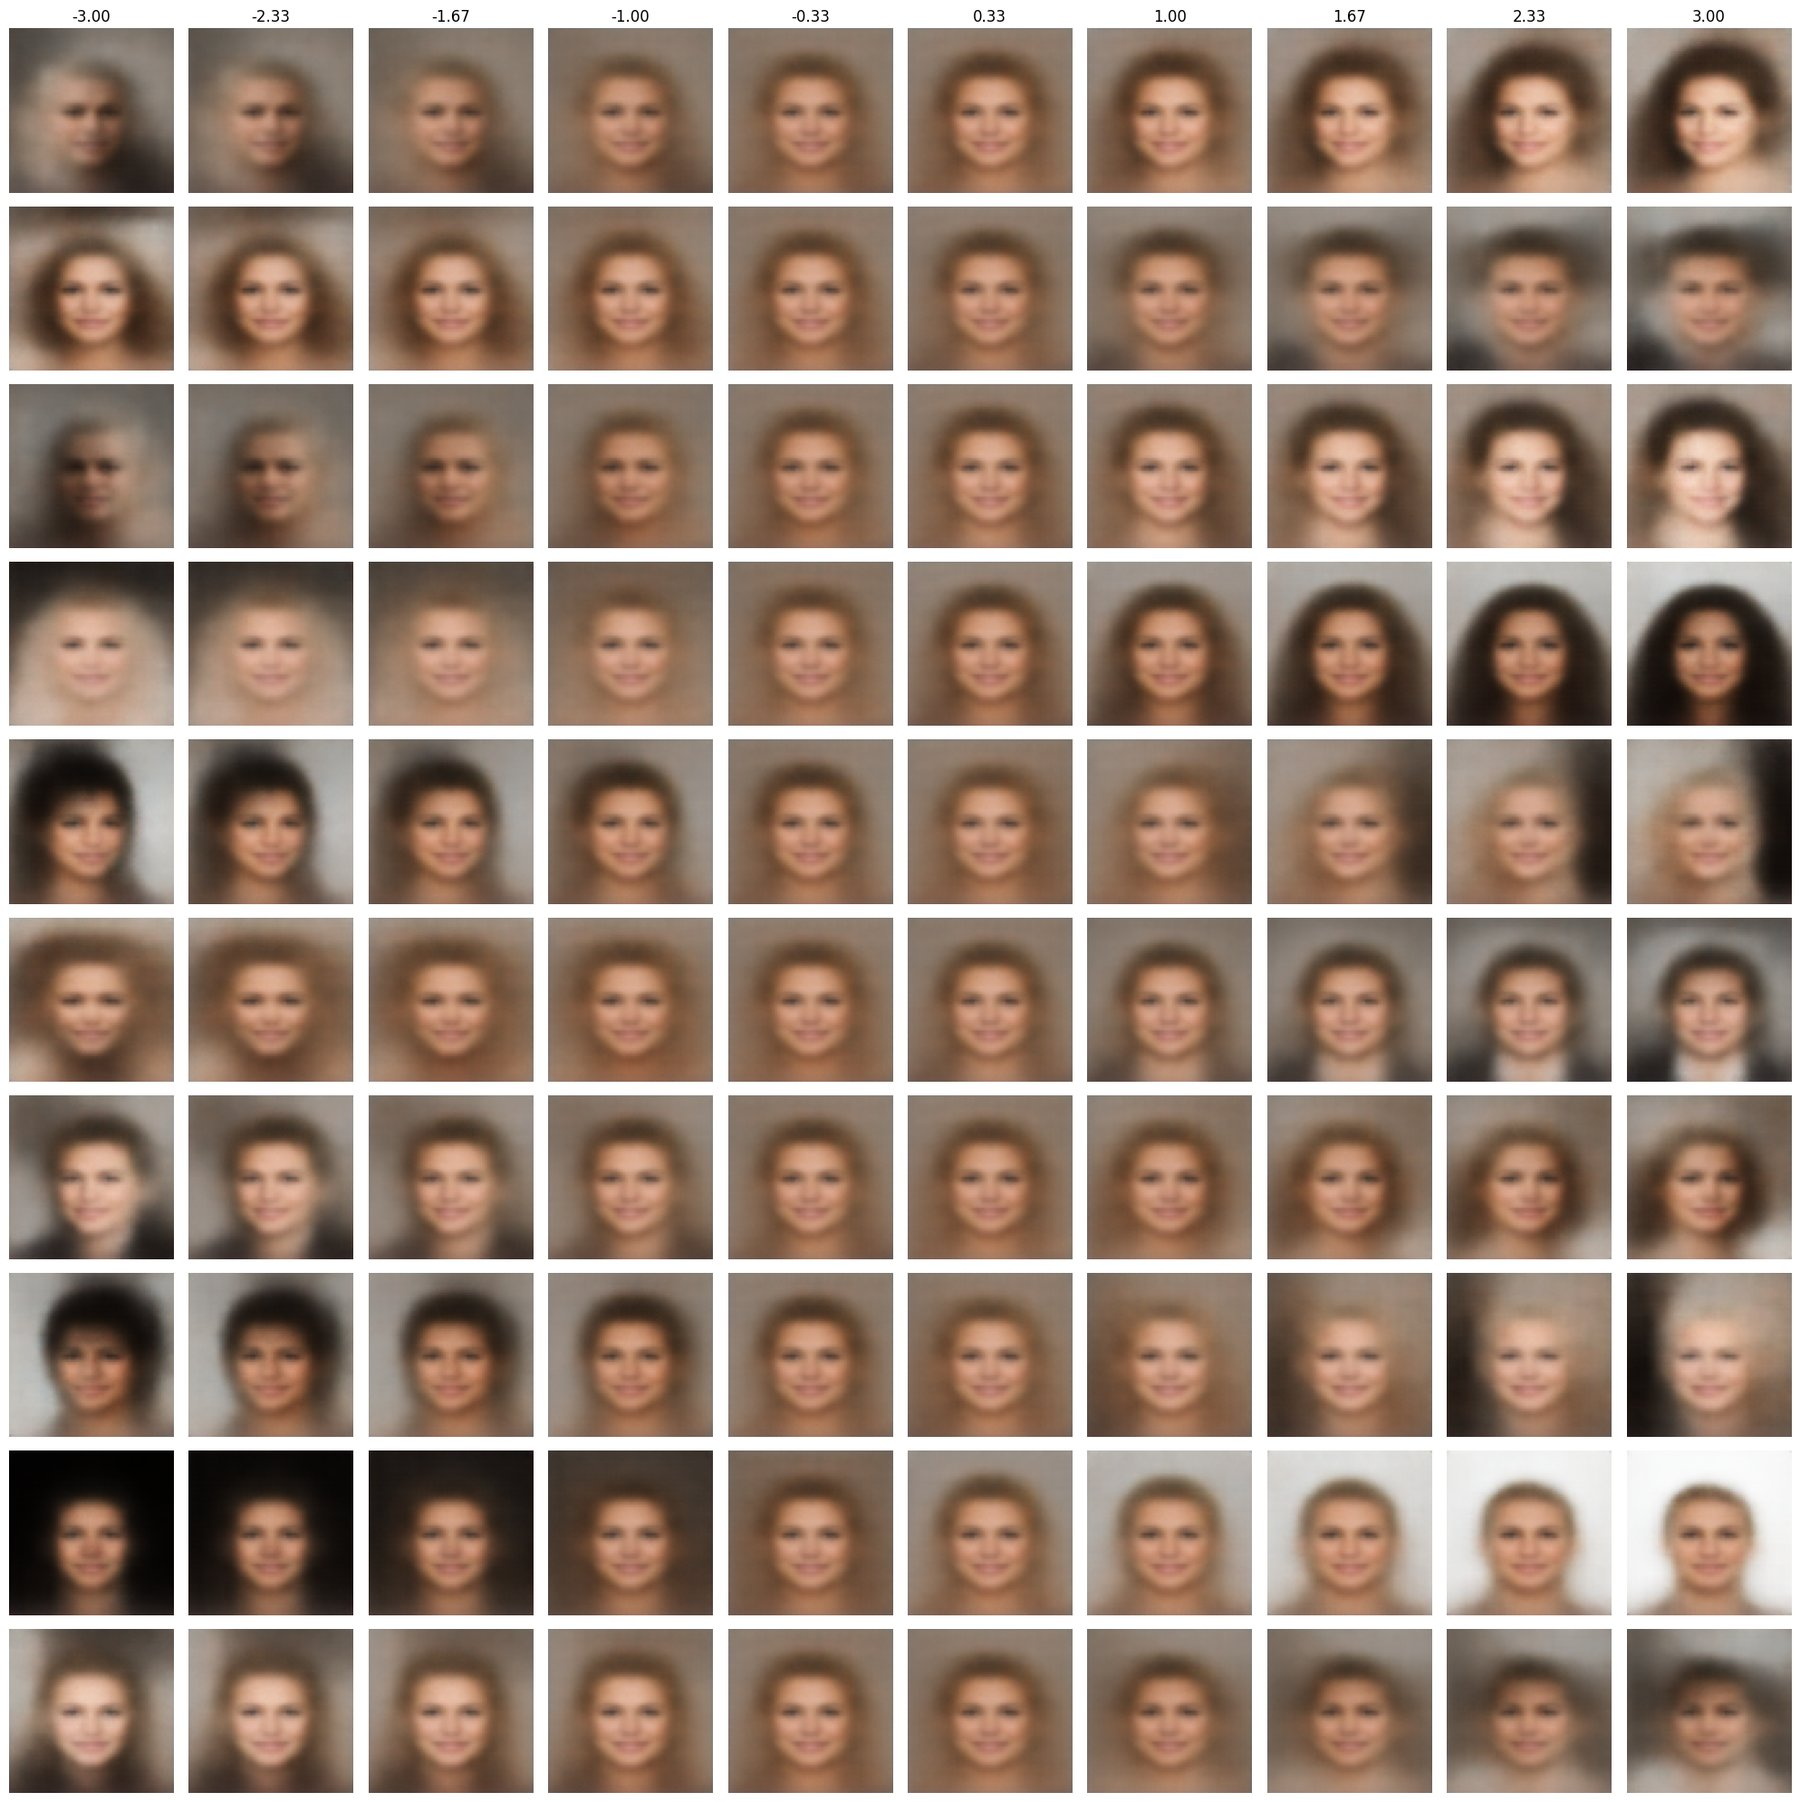

Chapter 2 | Beta = 5 | Latent Dim = 15 | Num Samples = 10 | Variation Range = (-3, 3)


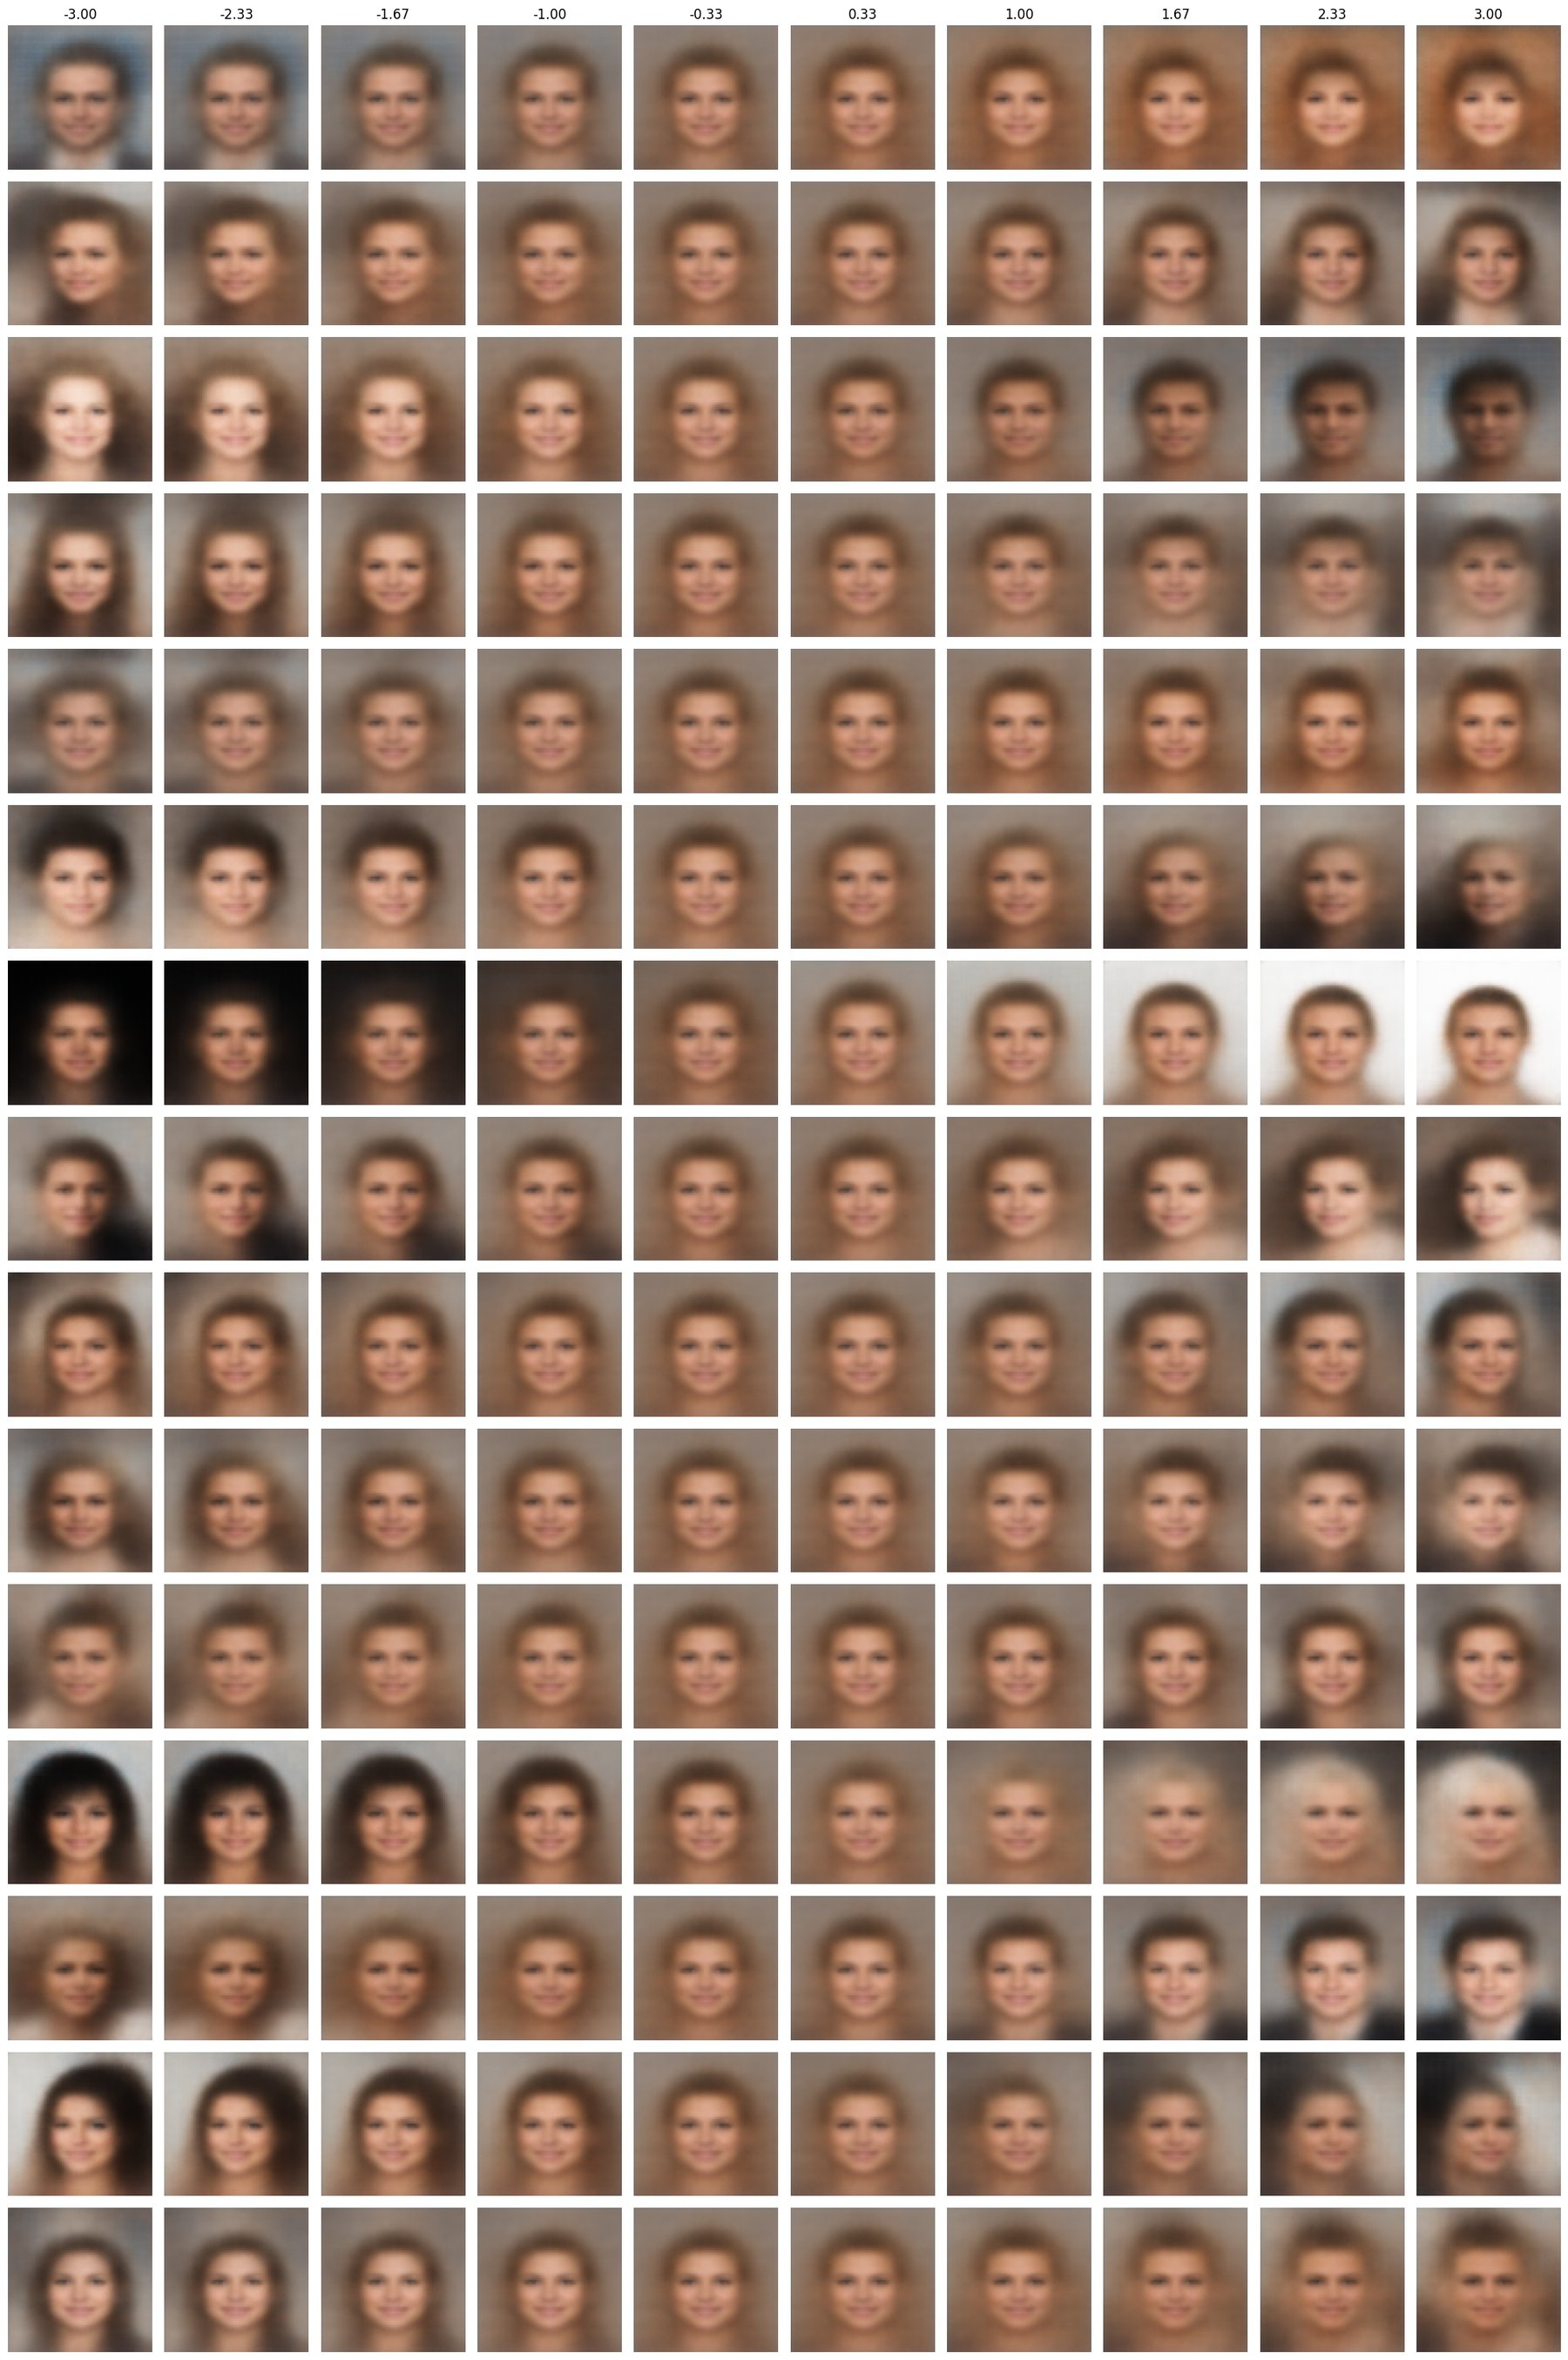

In [13]:
chapter2_results_df
for latent_dim in CH2_LATENT_DIMS:
    print(f"Chapter 2 | Beta = {FIXED_BETA} | Latent Dim = {latent_dim} | Num Samples = {CH2_DEFAULT_NUM_SAMPLES} | Variation Range = {CH2_DEFAULT_VARIATION_RANGE}")
    visualize_disentangled_latent_factors(chapter2_models[latent_dim], latent_dim=latent_dim, num_samples=CH2_DEFAULT_NUM_SAMPLES, variation_range=CH2_DEFAULT_VARIATION_RANGE)

Chapter 2 | Beta = 5 | Latent Dim = 15 | Num Samples = 8 | Variation Range = (-3, 3)


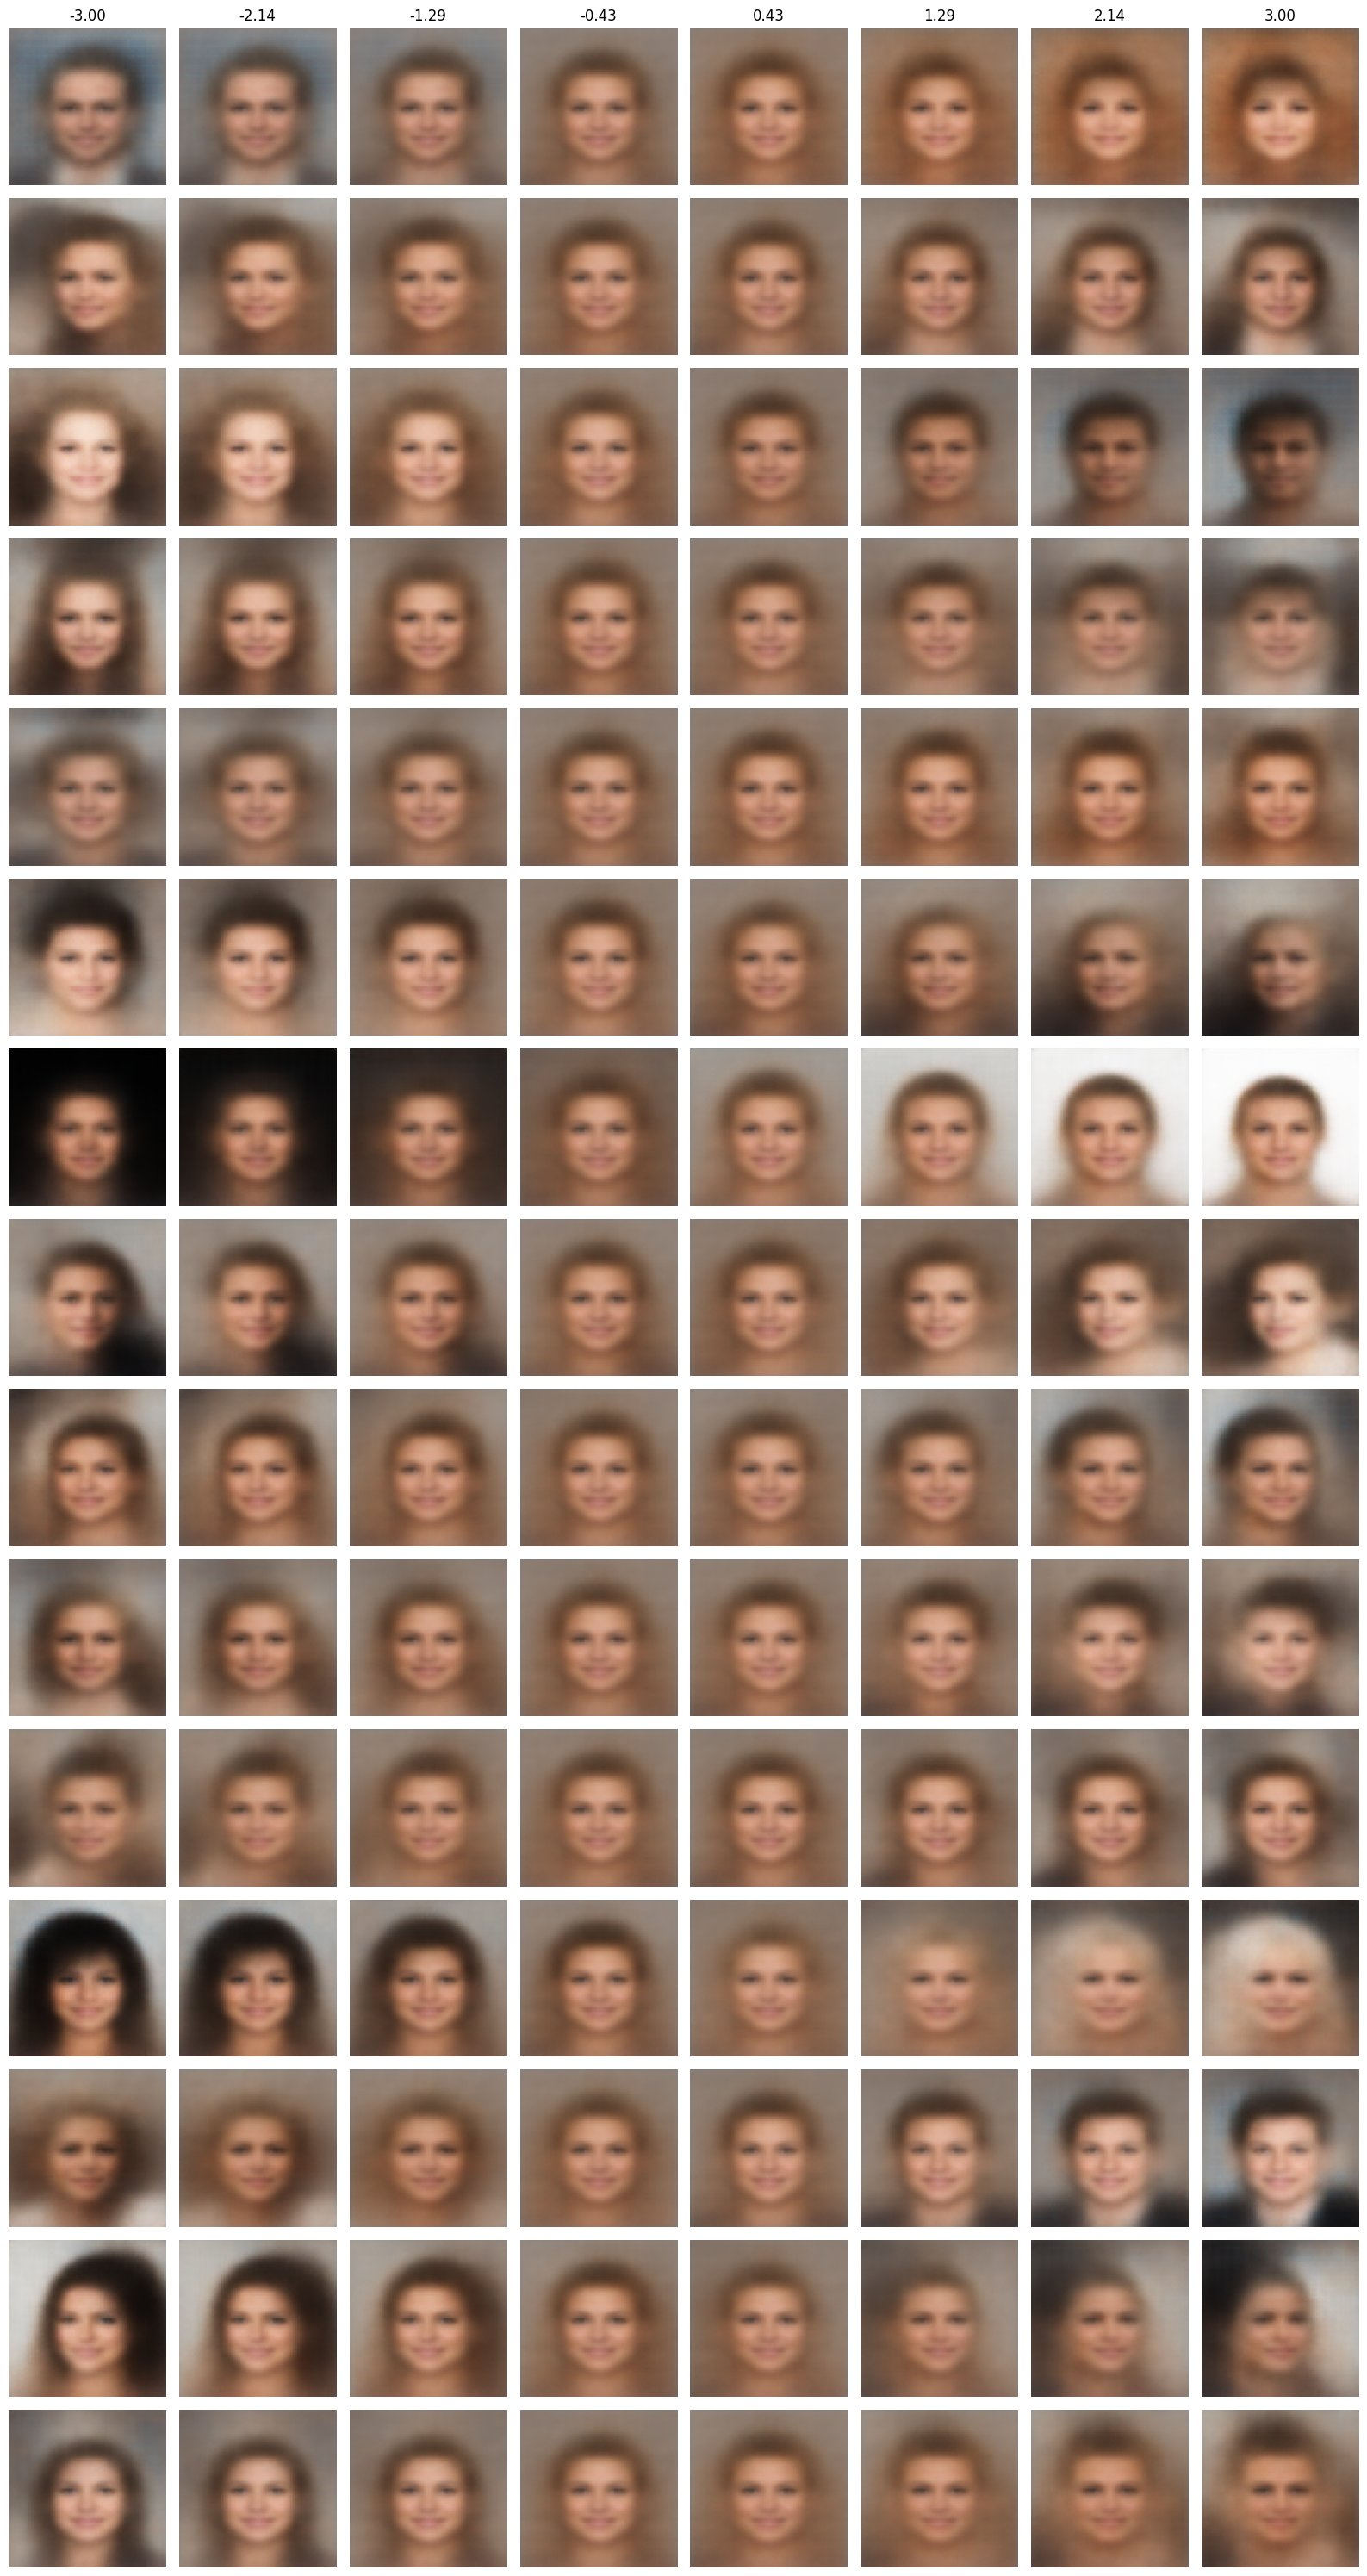

Chapter 2 | Beta = 5 | Latent Dim = 15 | Num Samples = 10 | Variation Range = (-3, 3)


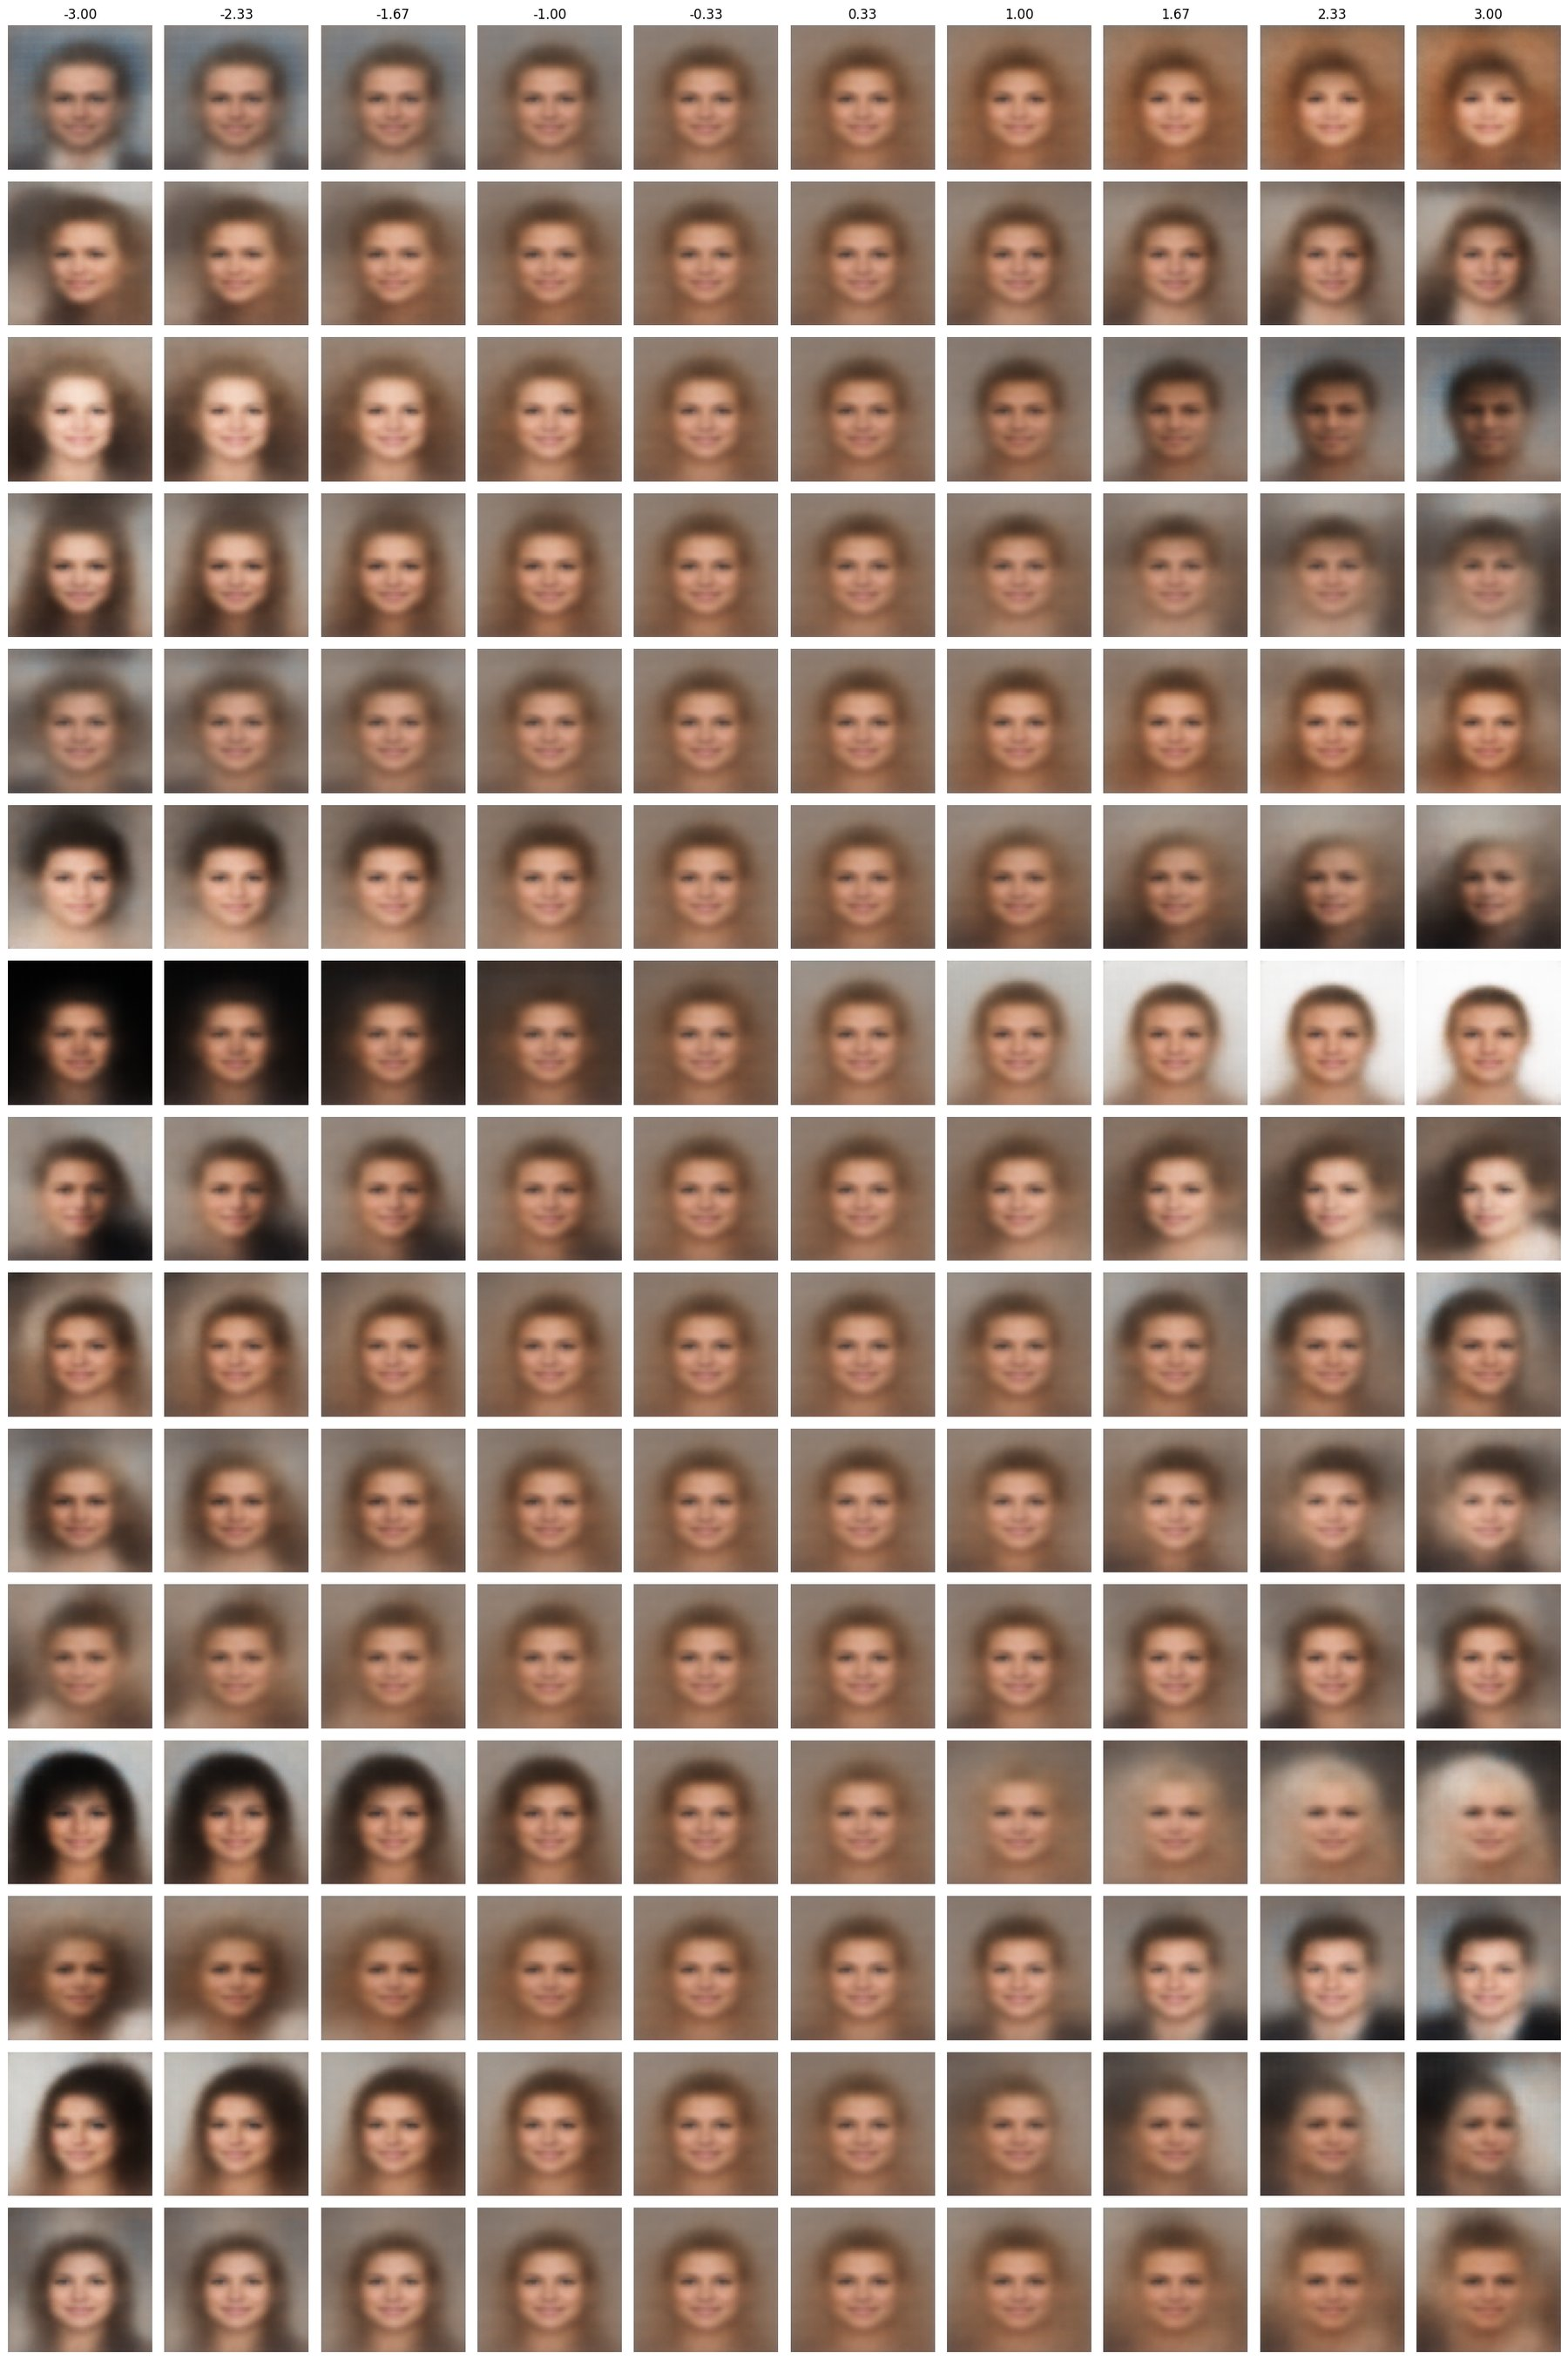

Chapter 2 | Beta = 5 | Latent Dim = 15 | Num Samples = 12 | Variation Range = (-3, 3)


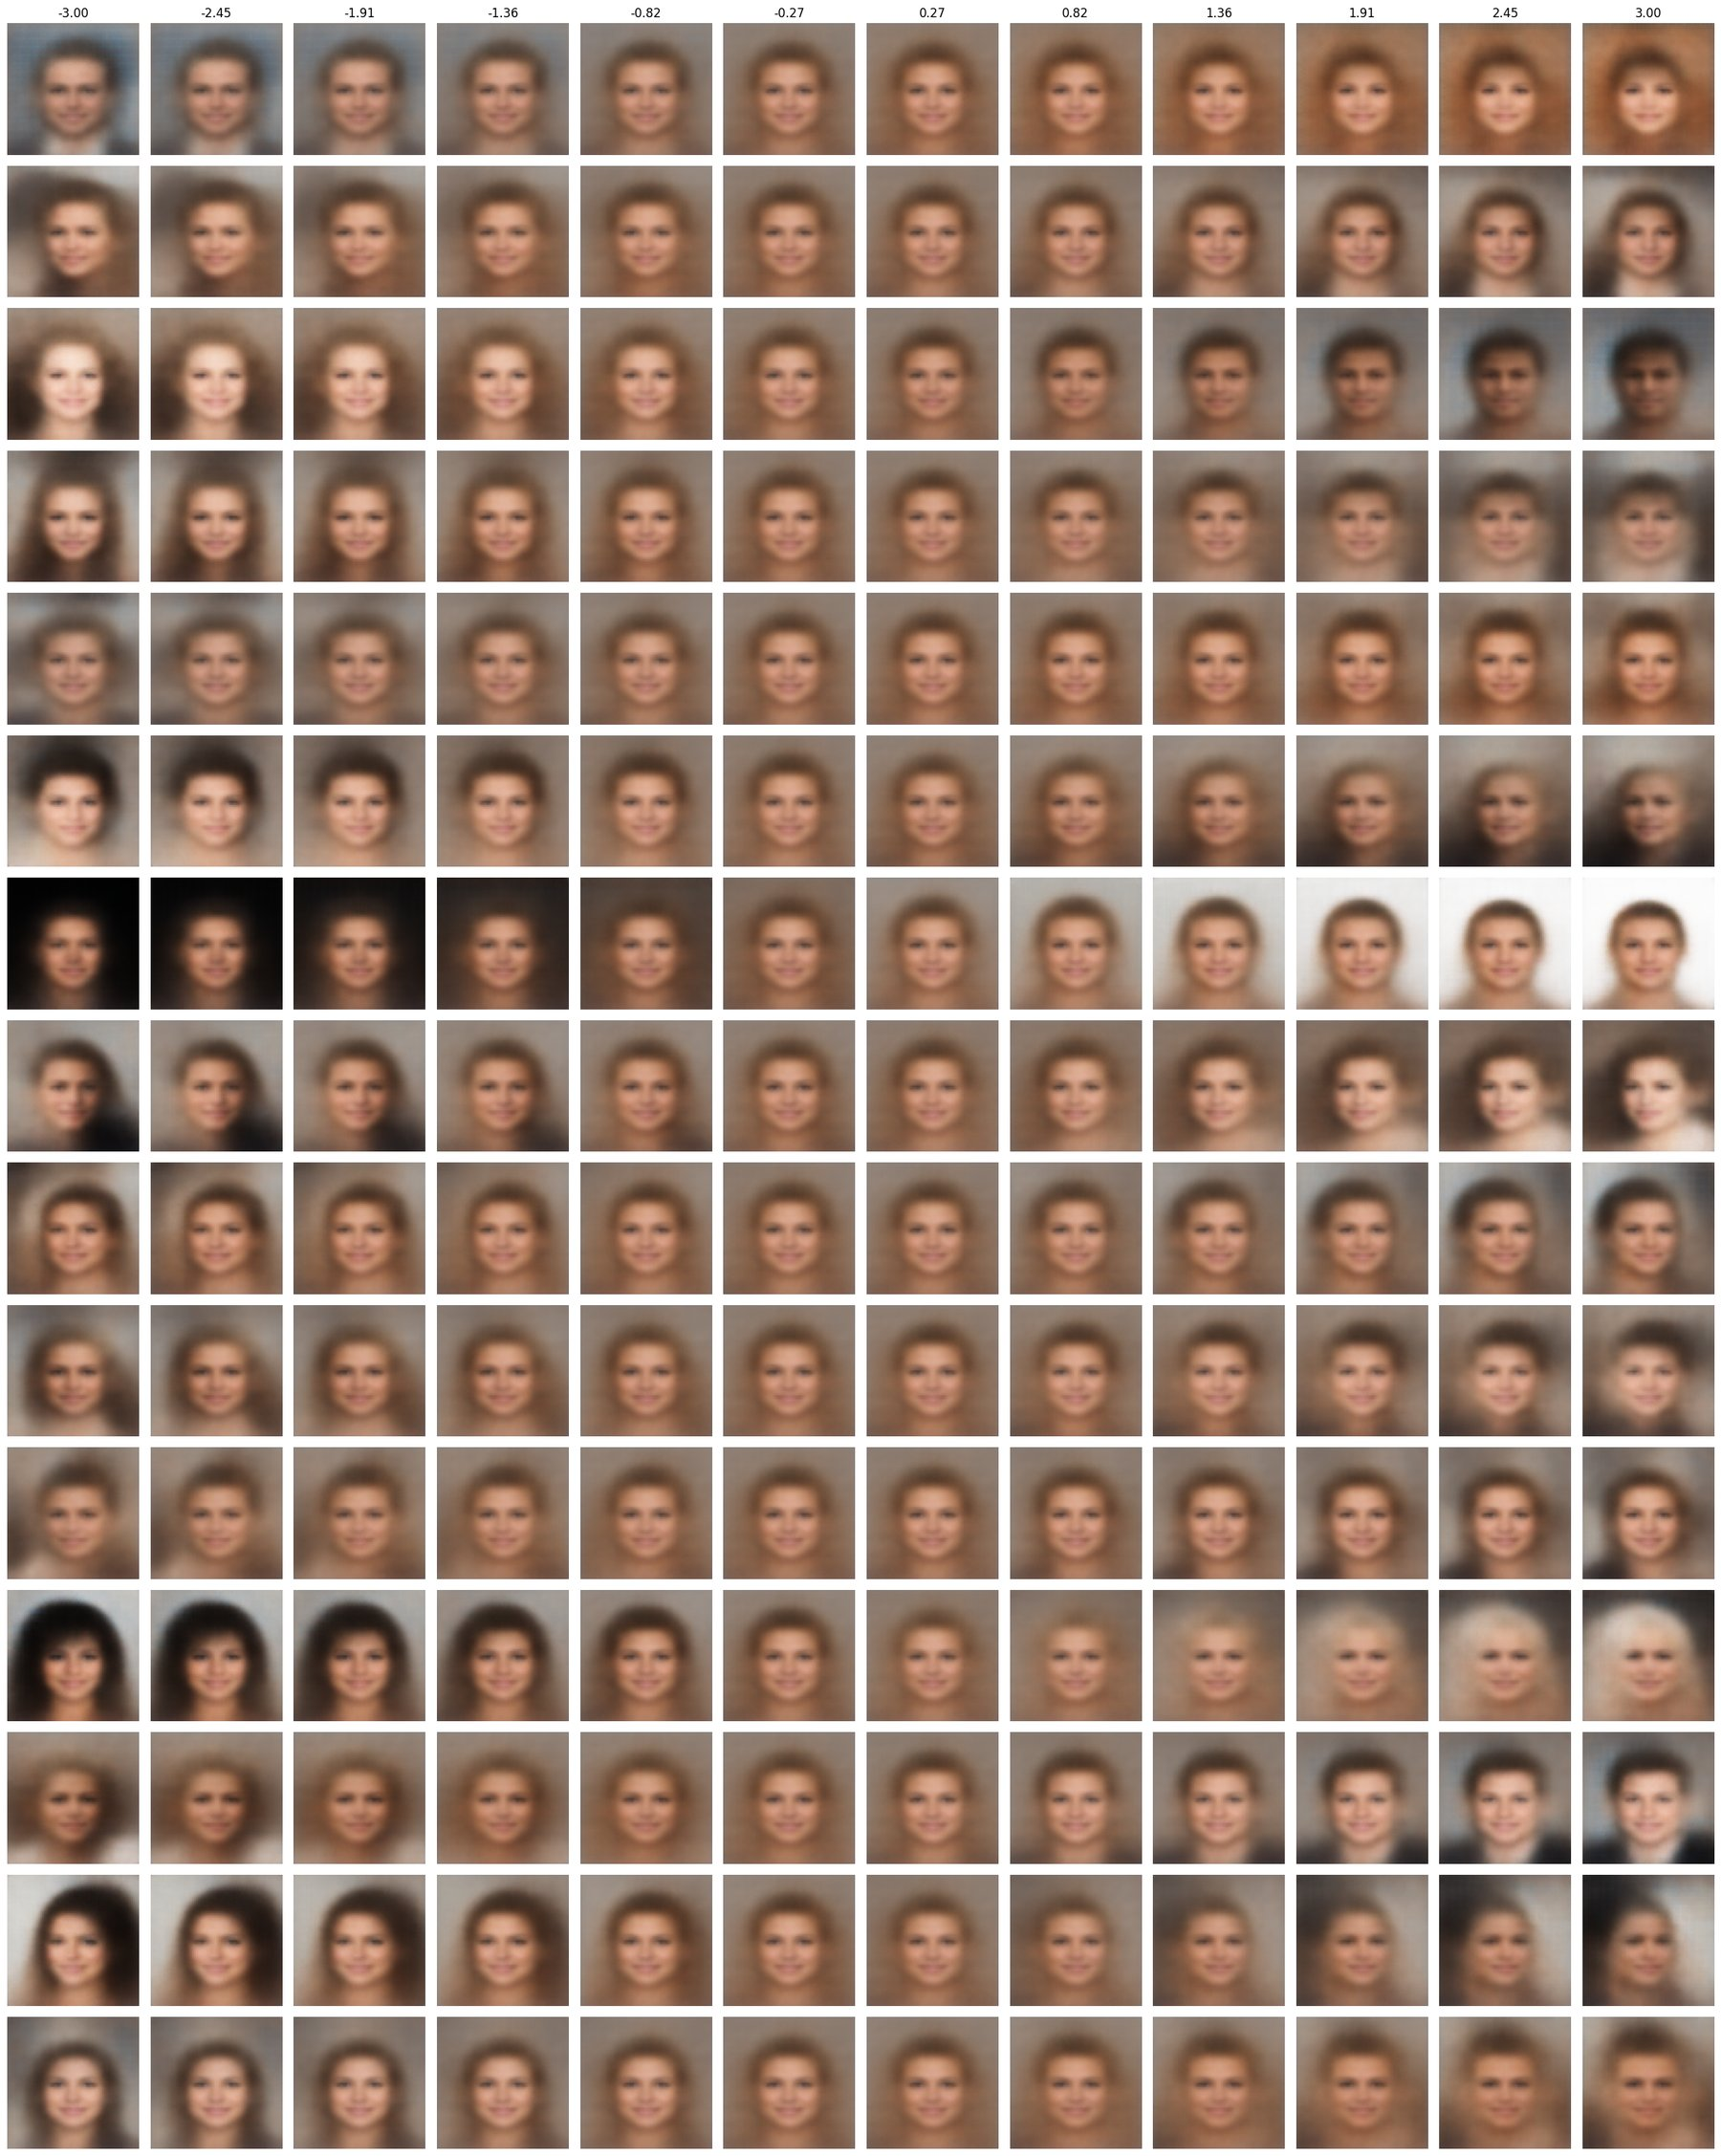

In [14]:
CH2_NUM_SAMPLES_EXPERIMENTS = [8, 10, 12]
for num_samples in CH2_NUM_SAMPLES_EXPERIMENTS:
    print(f"Chapter 2 | Beta = {FIXED_BETA} | Latent Dim = {BEST_LATENT_DIM} | Num Samples = {num_samples} | Variation Range = {CH2_DEFAULT_VARIATION_RANGE}")
    visualize_disentangled_latent_factors(chapter2_models[BEST_LATENT_DIM], latent_dim=BEST_LATENT_DIM, num_samples=num_samples, variation_range=CH2_DEFAULT_VARIATION_RANGE)

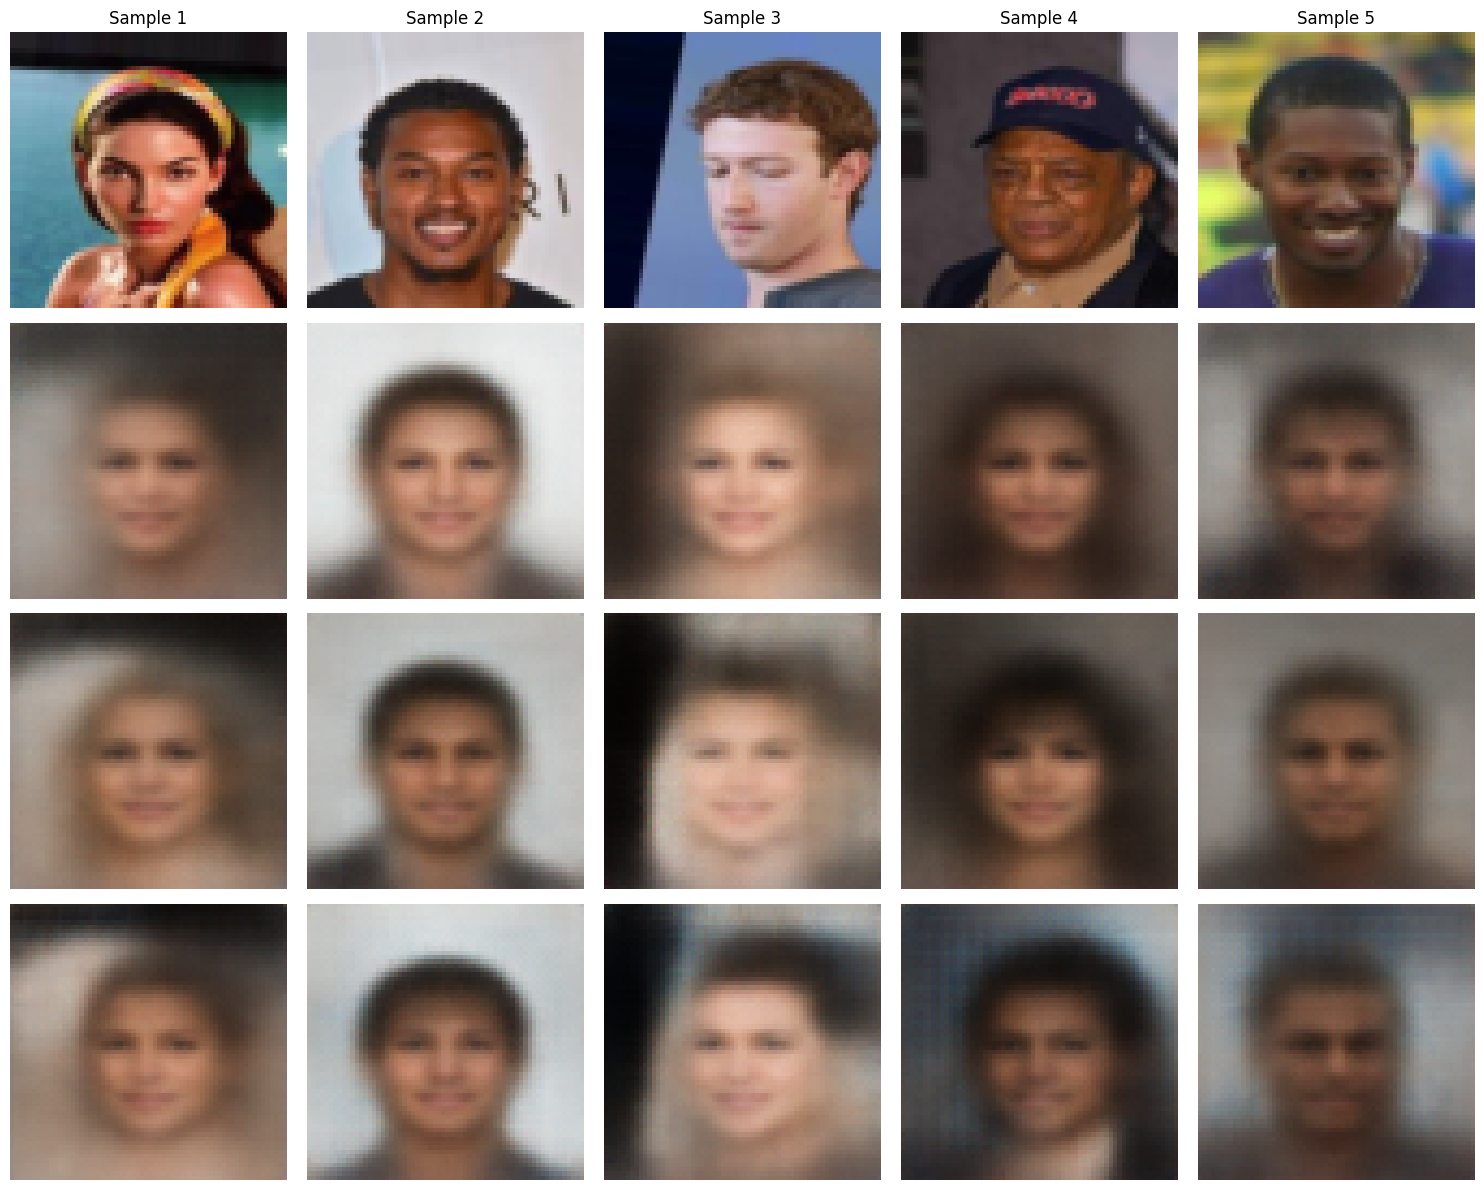

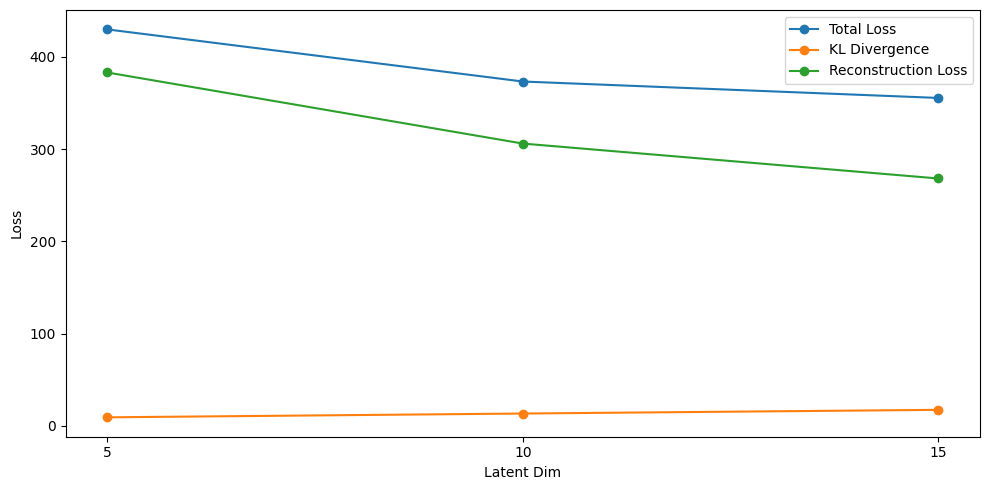

In [15]:
sample_images, _, _ = next(iter(test_loader))
sample_images = sample_images[:5].to(device)
fig, axes = plt.subplots(len(CH2_LATENT_DIMS) + 1, sample_images.size(0), figsize=(sample_images.size(0) * 3, (len(CH2_LATENT_DIMS) + 1) * 3))
for i in range(sample_images.size(0)):
    axes[0, i].imshow(np.clip(sample_images[i].permute(1, 2, 0).cpu().numpy(), 0, 1))
    axes[0, i].axis("off")
    axes[0, i].set_title(f"Sample {i+1}")
axes[0, 0].set_ylabel("Original")
with torch.no_grad():
    for row, latent_dim in enumerate(CH2_LATENT_DIMS, start=1):
        recon_x, _, _ = chapter2_models[latent_dim](sample_images)
        for col in range(sample_images.size(0)):
            axes[row, col].imshow(np.clip(recon_x[col].permute(1, 2, 0).cpu().numpy(), 0, 1))
            axes[row, col].axis("off")
        axes[row, 0].set_ylabel(f"z={latent_dim}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(chapter2_results_df["Latent Dim"], chapter2_results_df["Total Loss"], marker="o", label="Total Loss")
plt.plot(chapter2_results_df["Latent Dim"], chapter2_results_df["KL Divergence"], marker="o", label="KL Divergence")
plt.plot(chapter2_results_df["Latent Dim"], chapter2_results_df["Reconstruction Loss"], marker="o", label="Reconstruction Loss")
plt.xticks(CH2_LATENT_DIMS, CH2_LATENT_DIMS)
plt.xlabel("Latent Dim")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

<div style="text-align: center;">
    <h1 style="color: rgb(173, 216, 230); font-size: 50px; font-weight: bold;">
        ❄️ <span style="color: white;">Chapter 3</span> -
        <span style="color: rgb(173, 216, 230);">Winter</span> ❄️
        <span style="color: white;">[30 Points]</span>
    </h1>
    <hr style="height: 8px; width: 80%; background: linear-gradient(to right, white, rgb(173, 216, 230), white); border: none; margin-top: 10px; margin-bottom: 10px;">
</div>


<!-- SPORE WARNING HEADER -->
<div style="width: 100%; text-align: center;">
    <h1 style="color: rgb(248, 247, 249); font-size: 50px; font-weight: bold;">
        ☣️ <b>WATCH OUT!</b>  
        <span style="color: rgb(130, 89, 214);">
            🦠 SPORES AHEAD!  
        </span>  
        <span style="color: rgb(255, 255, 255);">
            If You Breathe…....... <b>You’re Done!</b> 💀  
        </span>
    </h1>
    <hr style="height: 8px; width: 100%; background: linear-gradient(to right, white, rgb(130, 89, 214), white); border: none; margin-top: 10px; margin-bottom: 10px;">
</div>

<!-- SPORE-INFESTED IMAGES -->
<div style="text-align: center;">
    <img src="TLOU8.jpg" style="width: 48%; height: 1100px; filter: brightness(80%) contrast(110%) saturate(120%); margin-right: 10px; border: 5px solid rgb(130, 89, 214);">
    <img src="TLOU7.jpg" style="width: 48%; height: 1100px; filter: brightness(80%) contrast(110%) saturate(120%); border: 5px solid rgb(130, 89, 214);">
</div>

<!-- SPORE LORE WITH DRAMATIC BACKGROUND -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(130, 89, 214, 0.6);">
    
<b>Ellie moves cautiously through the ruins of Hollywood.</b>  
A dead city, swallowed by time. Silent. Abandoned.  

Until she sees it—  

A <b>thick, swirling mist</b> floating in the dim light.  
Particles drift in the air like specks of **death itself**.  

🦠 **SPORES.** Thick. Dense. **Lethal.**  

She tightens her mask.  
Her breath slows. **She has to move forward.**  

Every inch of the air is <b>infected</b>,  
the last whispers of a world long gone.  

</div>

<!-- SUBHEADING: WHAT ARE SPORES? -->
<div style="padding: 10px; text-align: center;">
    <h2 style="color: white; font-size: 30px; font-weight: bold;">
        🦠 <b>What Are Spores?</b>  
    </h2>
</div>

<!-- SPORE LORE WITH DRAMATIC BACKGROUND -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(130, 89, 214, 0.6);">
    
<b>According to <span style="color: rgb(130, 89, 214);">The Last of Us lore</span></b>, Spores are  
<b>airborne fungal particles</b> carrying the Cordyceps infection.  
They <b>linger in enclosed spaces</b>, unseen, yet deadly.  

<br>  

💀 <b>Without protection, exposure to Spores is a death sentence.</b> 💀  

<br>

Ellie, immune yet suffocating in the thick air, moves cautiously.  

<br>

<b>The air tastes wrong. The silence is suffocating.</b>  

<br>

Then—  

<br>

🚨 <b>This is where everything changes.</b> 🚨  

</div>


<!-- SUBHEADING: NO MORE SKELETON CODE -->
<div style="padding: 10px; text-align: center;">
    <h2 style="color: white; font-size: 30px; font-weight: bold;">
        💀 <b>NO MORE SKELETON CODE!</b> 💀
    </h2>
</div>

<!-- CINEMATIC BLOCK -->
<div style="padding: 30px; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(130, 89, 214, 0.6);">
    <b>With limited visibility, no outside help, and nowhere to run…</b>  
    Ellie must rely on her instincts.  
    <b>And so must YOU.</b>  
</div>

<!-- FINAL MESSAGE -->
<div style="padding: 30px; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(130, 89, 214, 0.6);">
    She <b>must</b> find the WLF. She <b>must</b> finish what she started.  
    <b>You have unfinished business too.</b>  
</div>


<div style="width: 100%; text-align: center;">
<h1 style="color:rgb(244, 244, 245); font-size: 40px; font-weight: bold;">
    <span style="text-decoration-color: white;">Let's Continue the:
    <span style="color:rgb(130, 89, 214);">Hunt</span></span> 🐾
</h1>
<hr style="height: 10px; width: 100%; background-color: white; border: none; margin-top: 10px; margin-bottom: 10px;">
</div>

## 🛠️ **Your Task: Analyzing Disentangled Representations Across β Values**  

Ellie has learned to distinguish the **Infected from the WLF** using deep learning, but now she must **fine-tune her approach**. Different **β-values** result in different **levels of disentanglement**—your job is to analyze and visualize them.

---

## **🎯 What You Need to Do:**
1️⃣ **Train a β-VAE model** for at least **4 different β values** (1, 5, 10, 50). --> No need to do this again if you already did it above then just use those models.
2️⃣ **Run the training process** for **at least 3 epochs** (you can train for longer).  --> Same procedure as above , i am just repeating the steps incase you do not want to scroll above.
3️⃣ **Save each trained model** separately. --> Ideally you should have done this before but not my fault if you did not , please train again then. No Way around this.
4️⃣ **Visualize the effect of β** on the learned latent space:  
   - Pick a **suitable variation range** (e.g., -3 to 3).  
   - Generate and plot **disentangled latent factors** for **each β value**.  
5️⃣ **Compare the results**—observe **how β affects disentanglement** and reconstruction quality.

---

## **📊 Visualizing the Disentangled Latent Factors**  

For each trained model, you must **vary each latent dimension** and generate corresponding images. The goal is to see **how different features change** when we tweak the latent variables.

🚀 **Your final visualization should include:**
- **Separate plots for each β value**.
- **Variations across latent dimensions**.
- **A comparison of how different β values affect feature disentanglement**.

---

💀 **Ellie's revenge isn't over yet**—and neither is your task!  
🔥 **Push forward, complete the visualizations, and see the true power of β-VAE!**  

---

In [16]:
# Code
analysis_models = {}
for beta in BETA_VALUES:
    checkpoint_path = os.path.join(SAVE_DIR, f"beta_vae_beta_{beta}.pth")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model = BetaVAE(latent_dim=checkpoint["latent_dim"], beta=checkpoint["beta"]).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    analysis_models[beta] = model
analysis_models.keys()

dict_keys([1, 5, 10, 50])

Beta = 1 | Latent Dim = 15


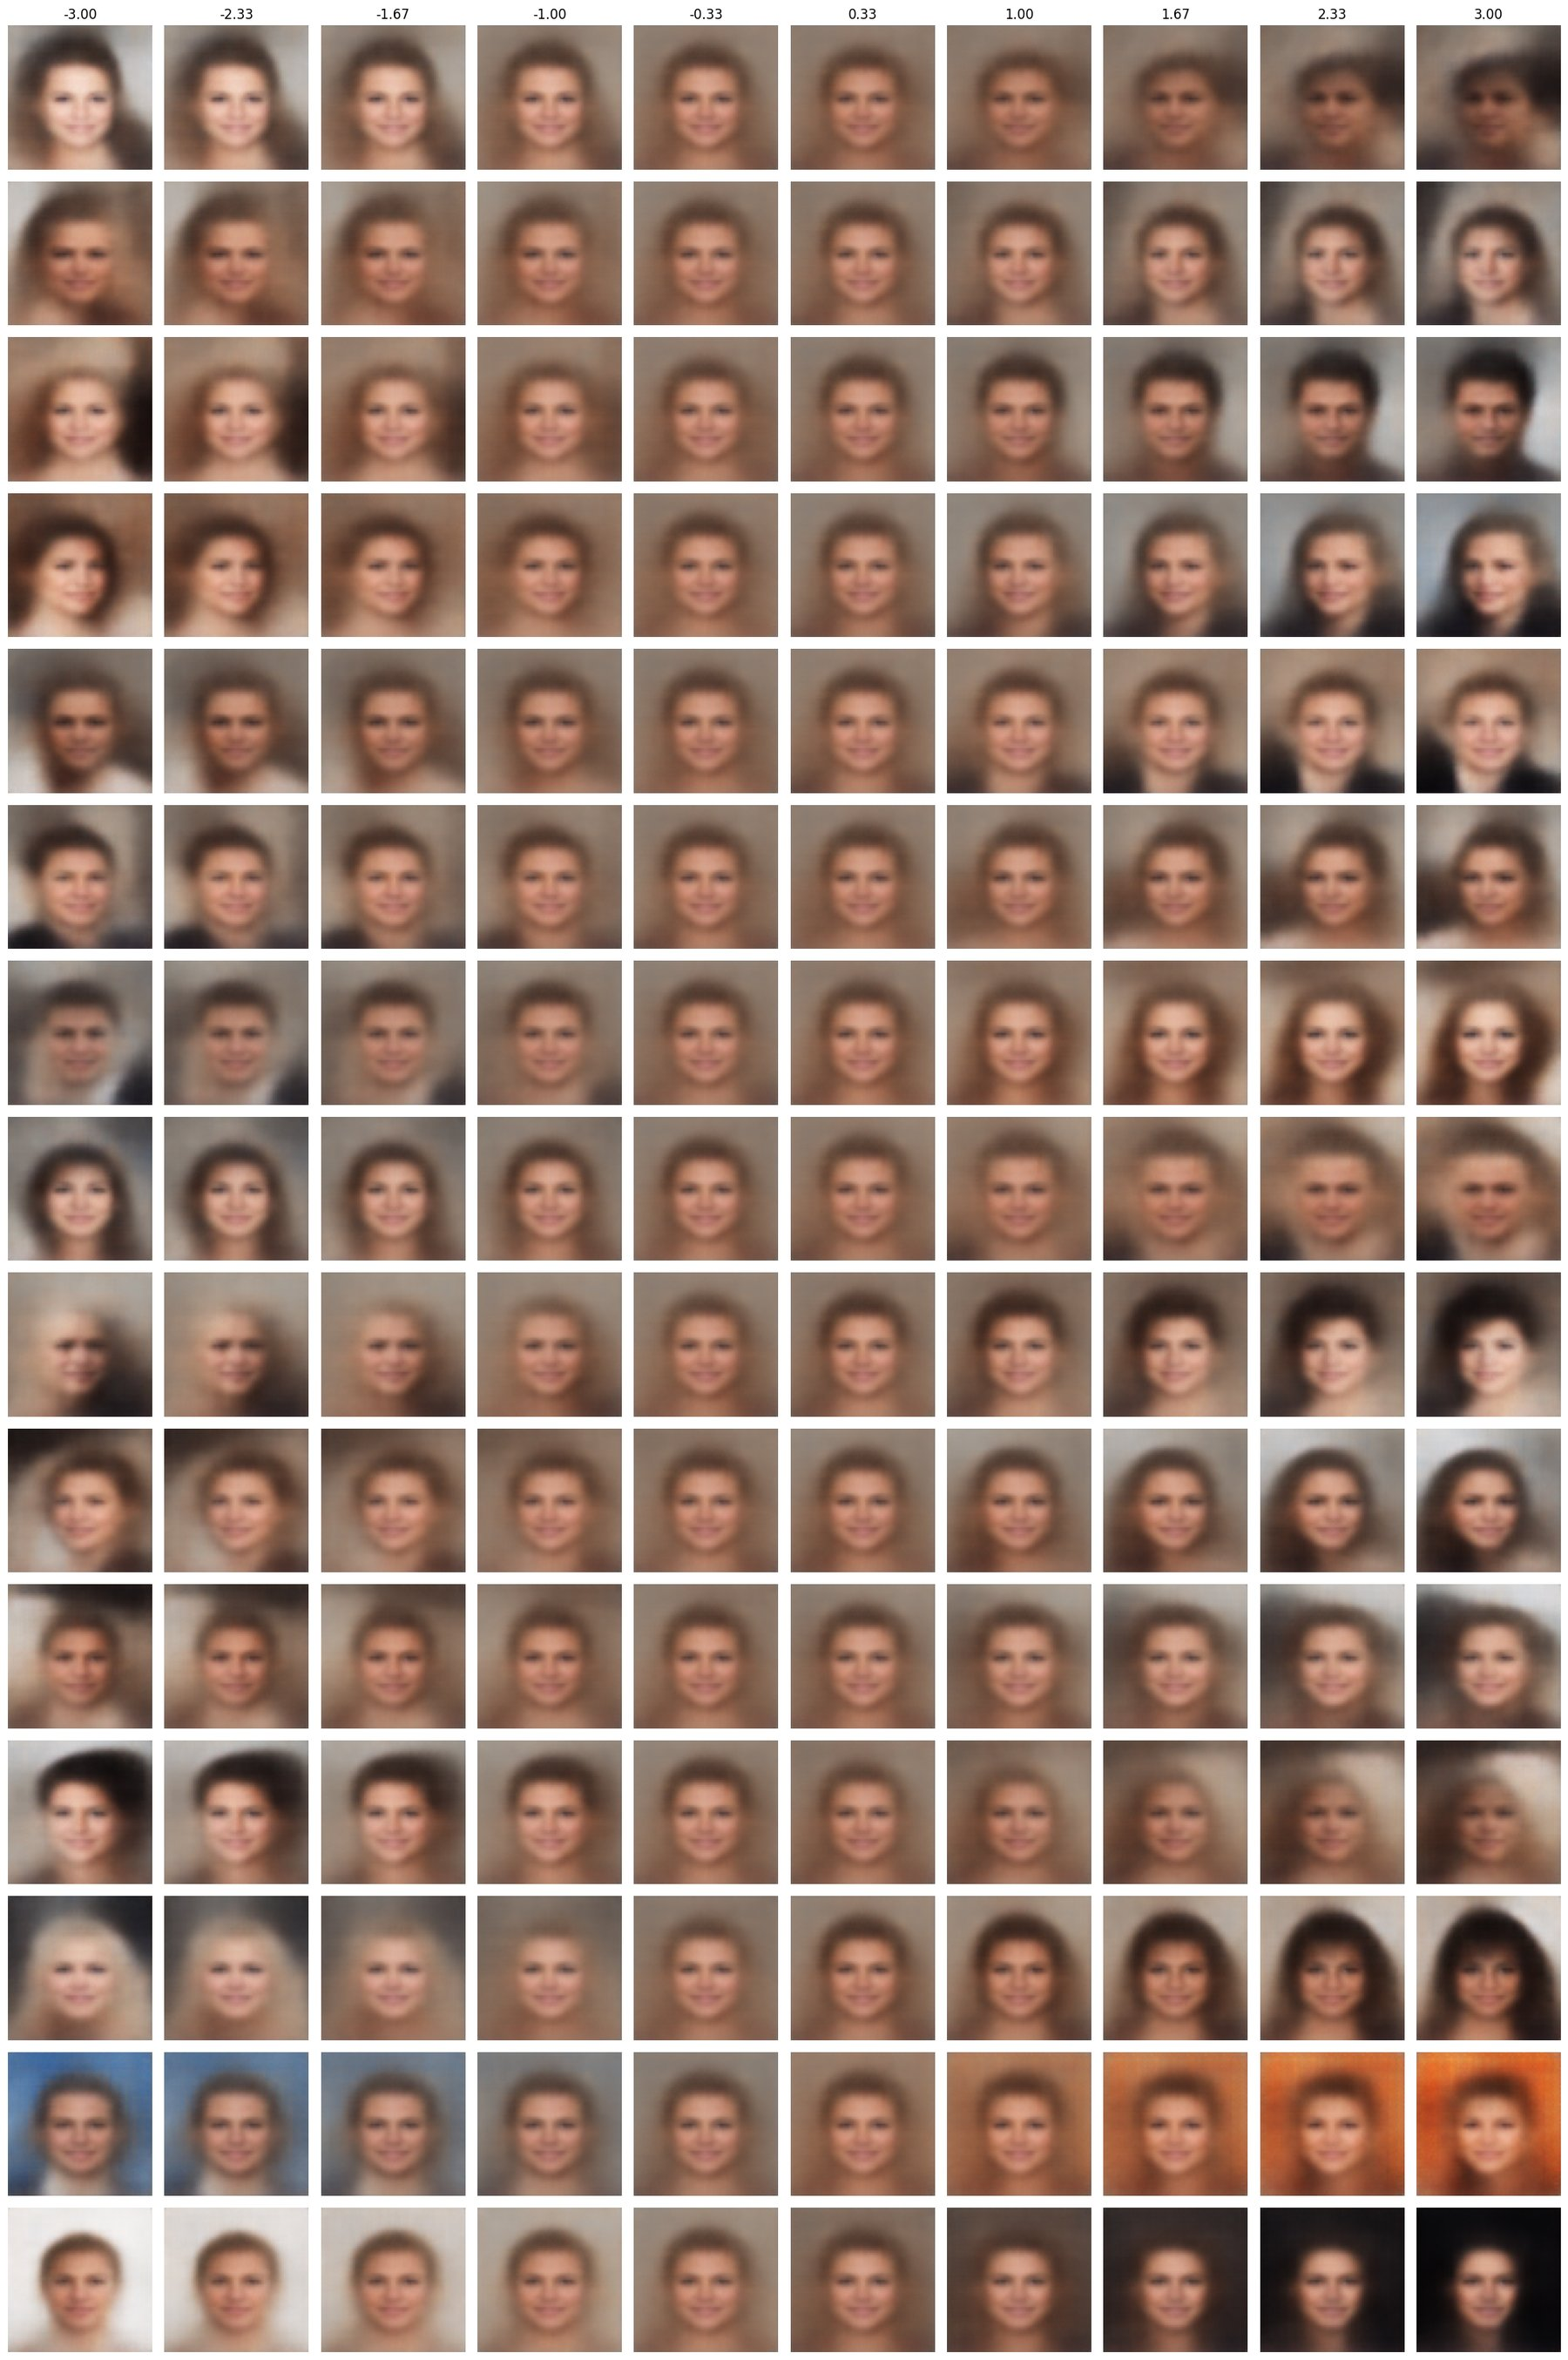

Beta = 5 | Latent Dim = 15


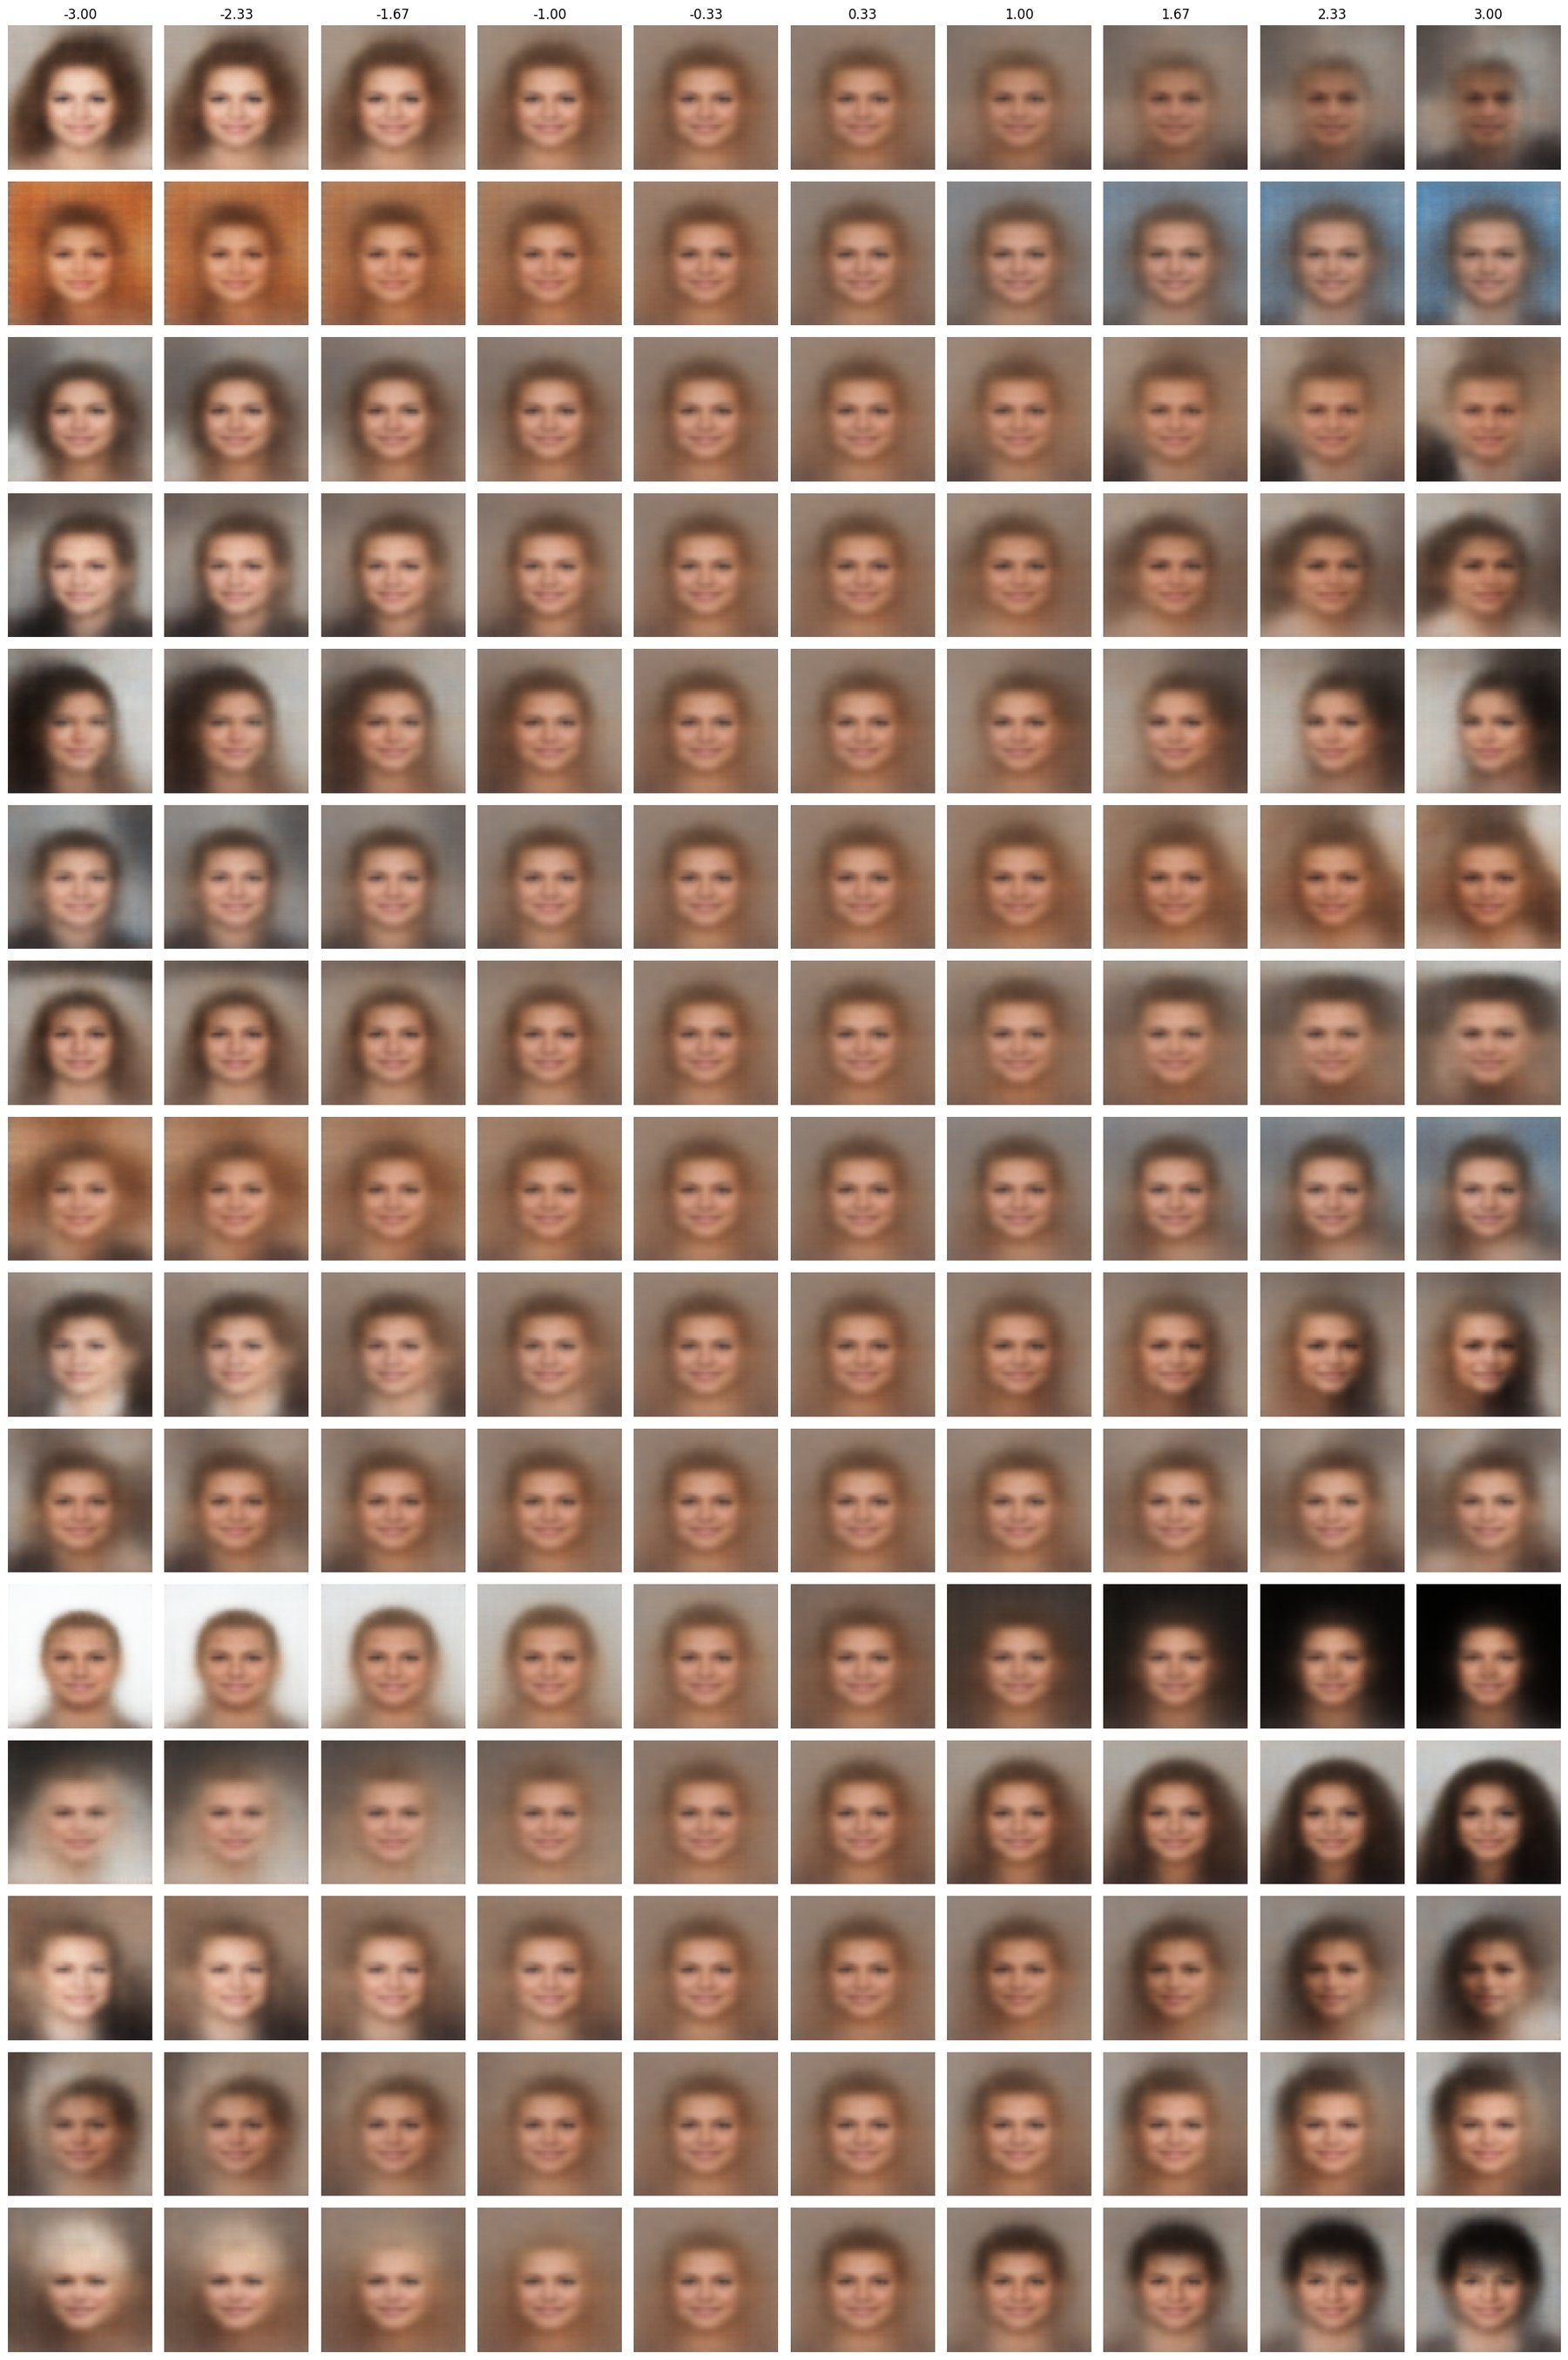

Beta = 10 | Latent Dim = 15


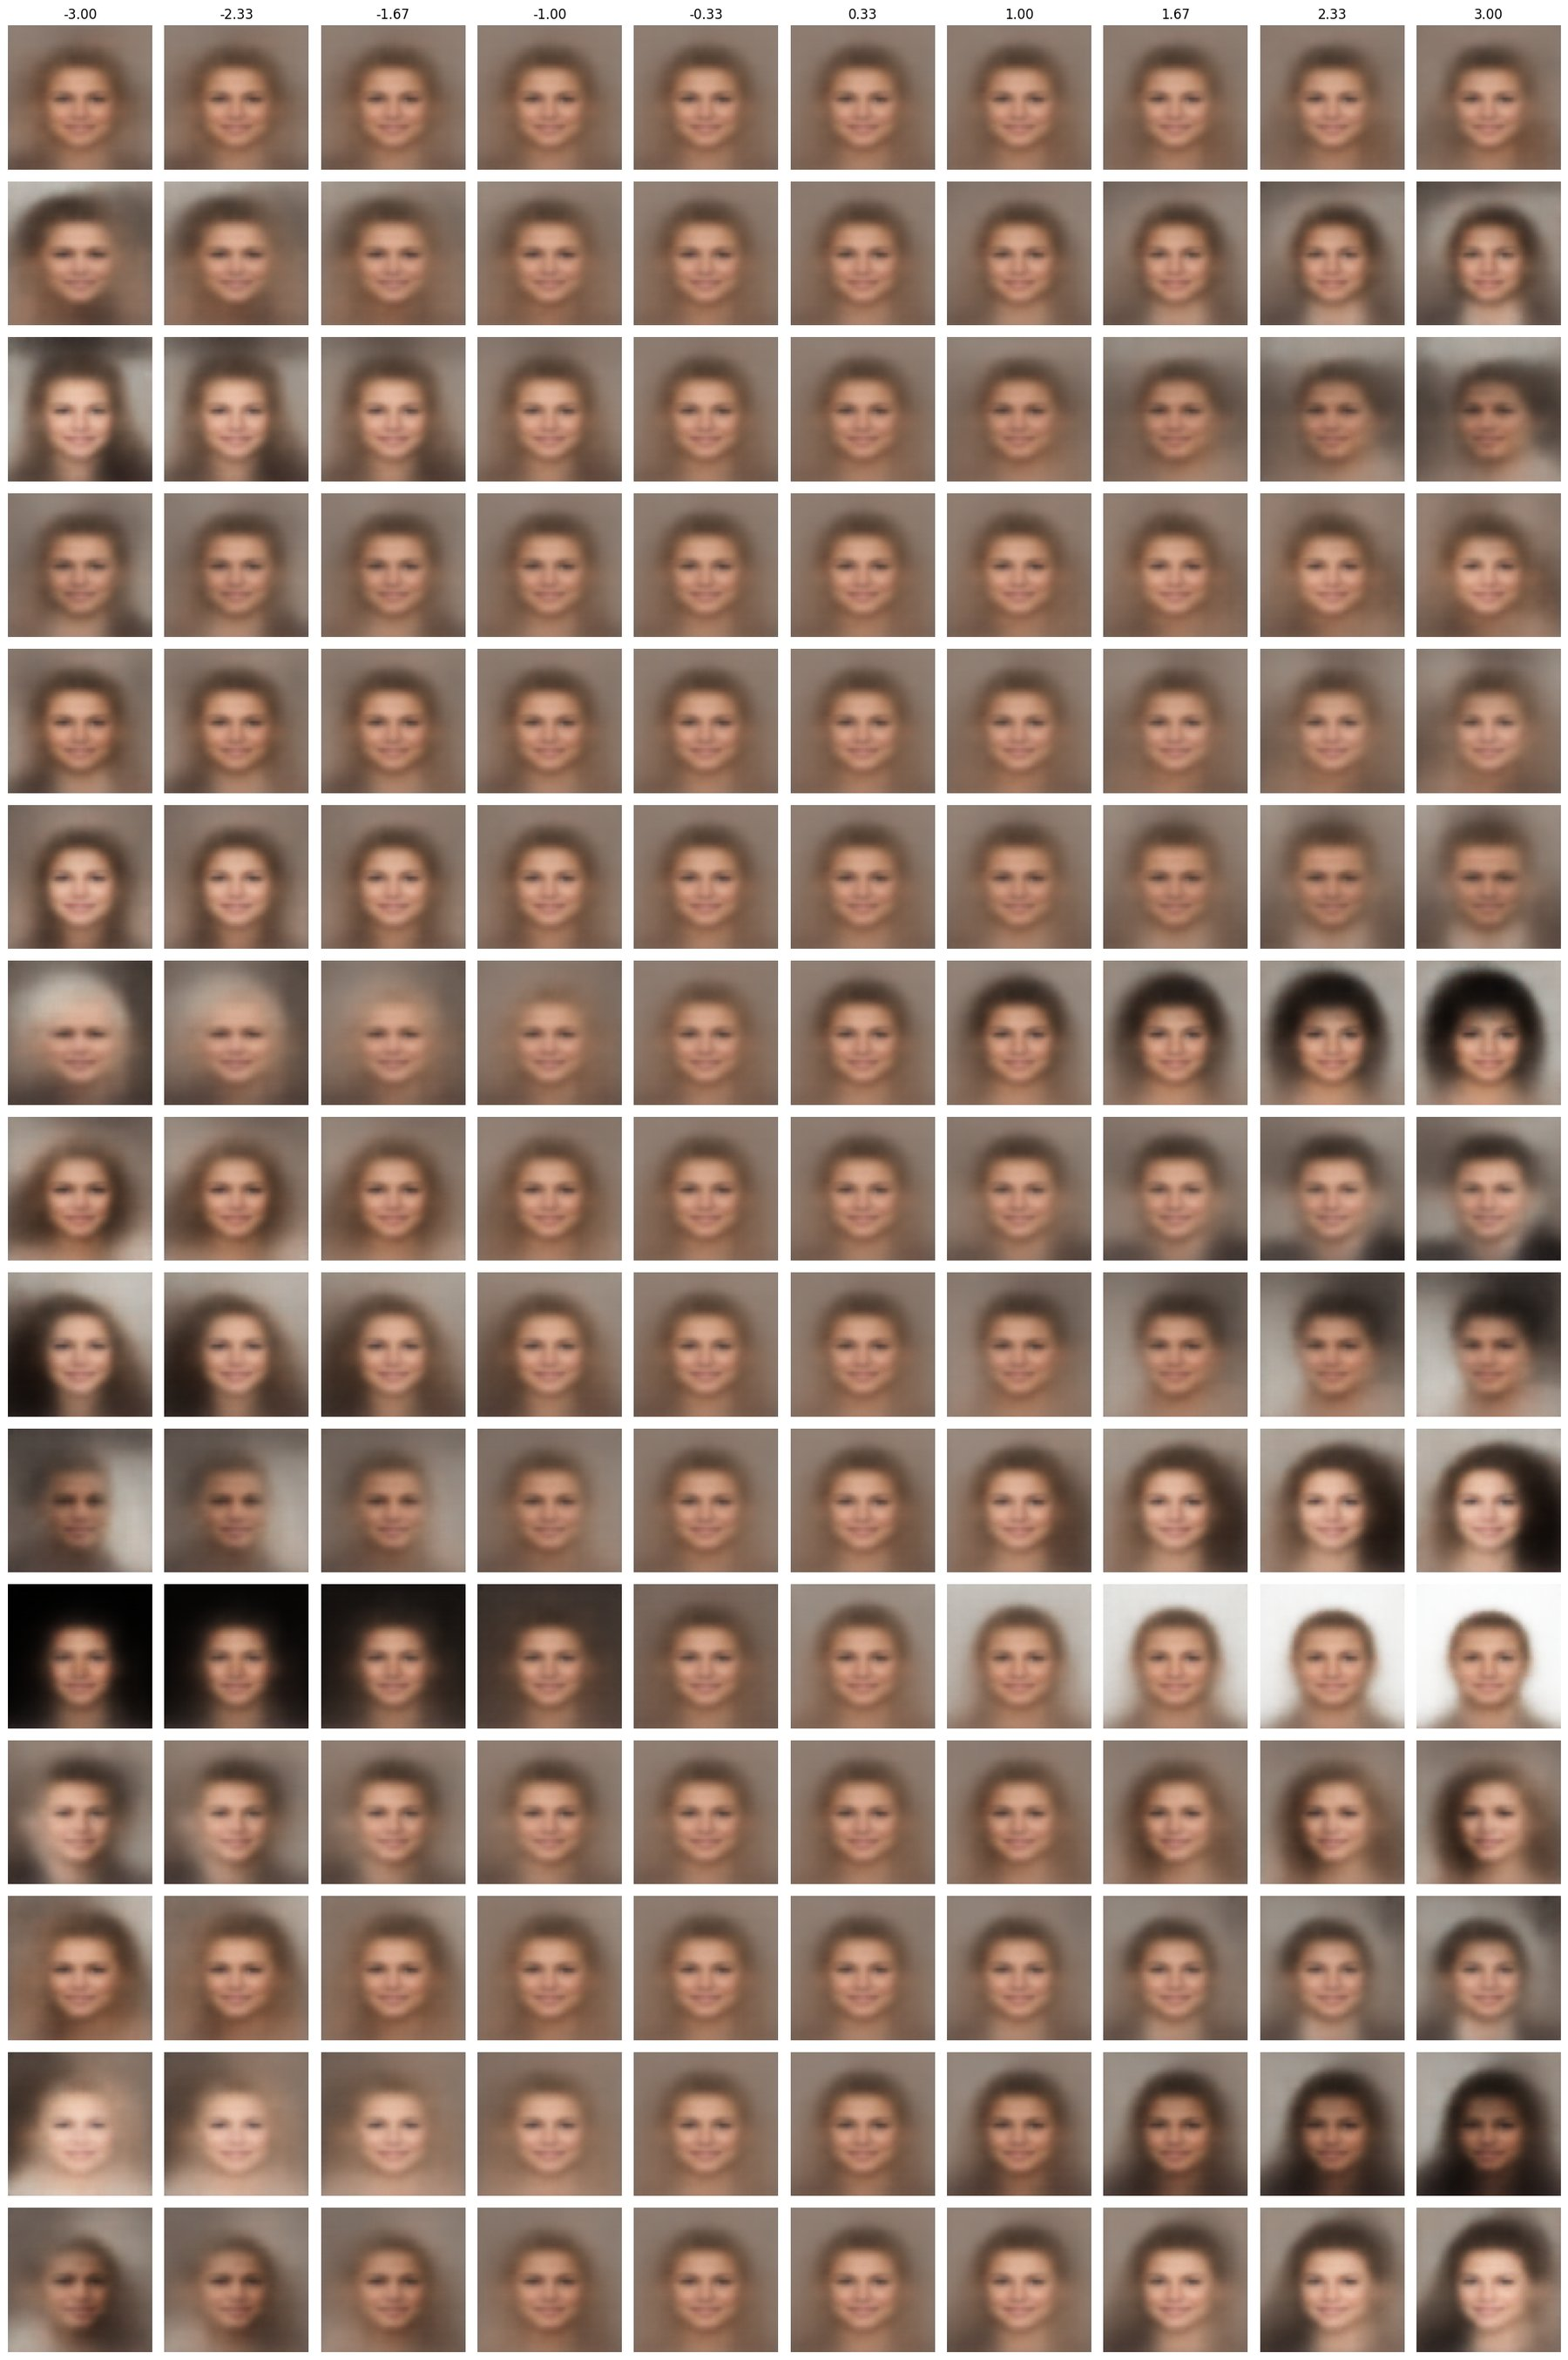

Beta = 50 | Latent Dim = 15


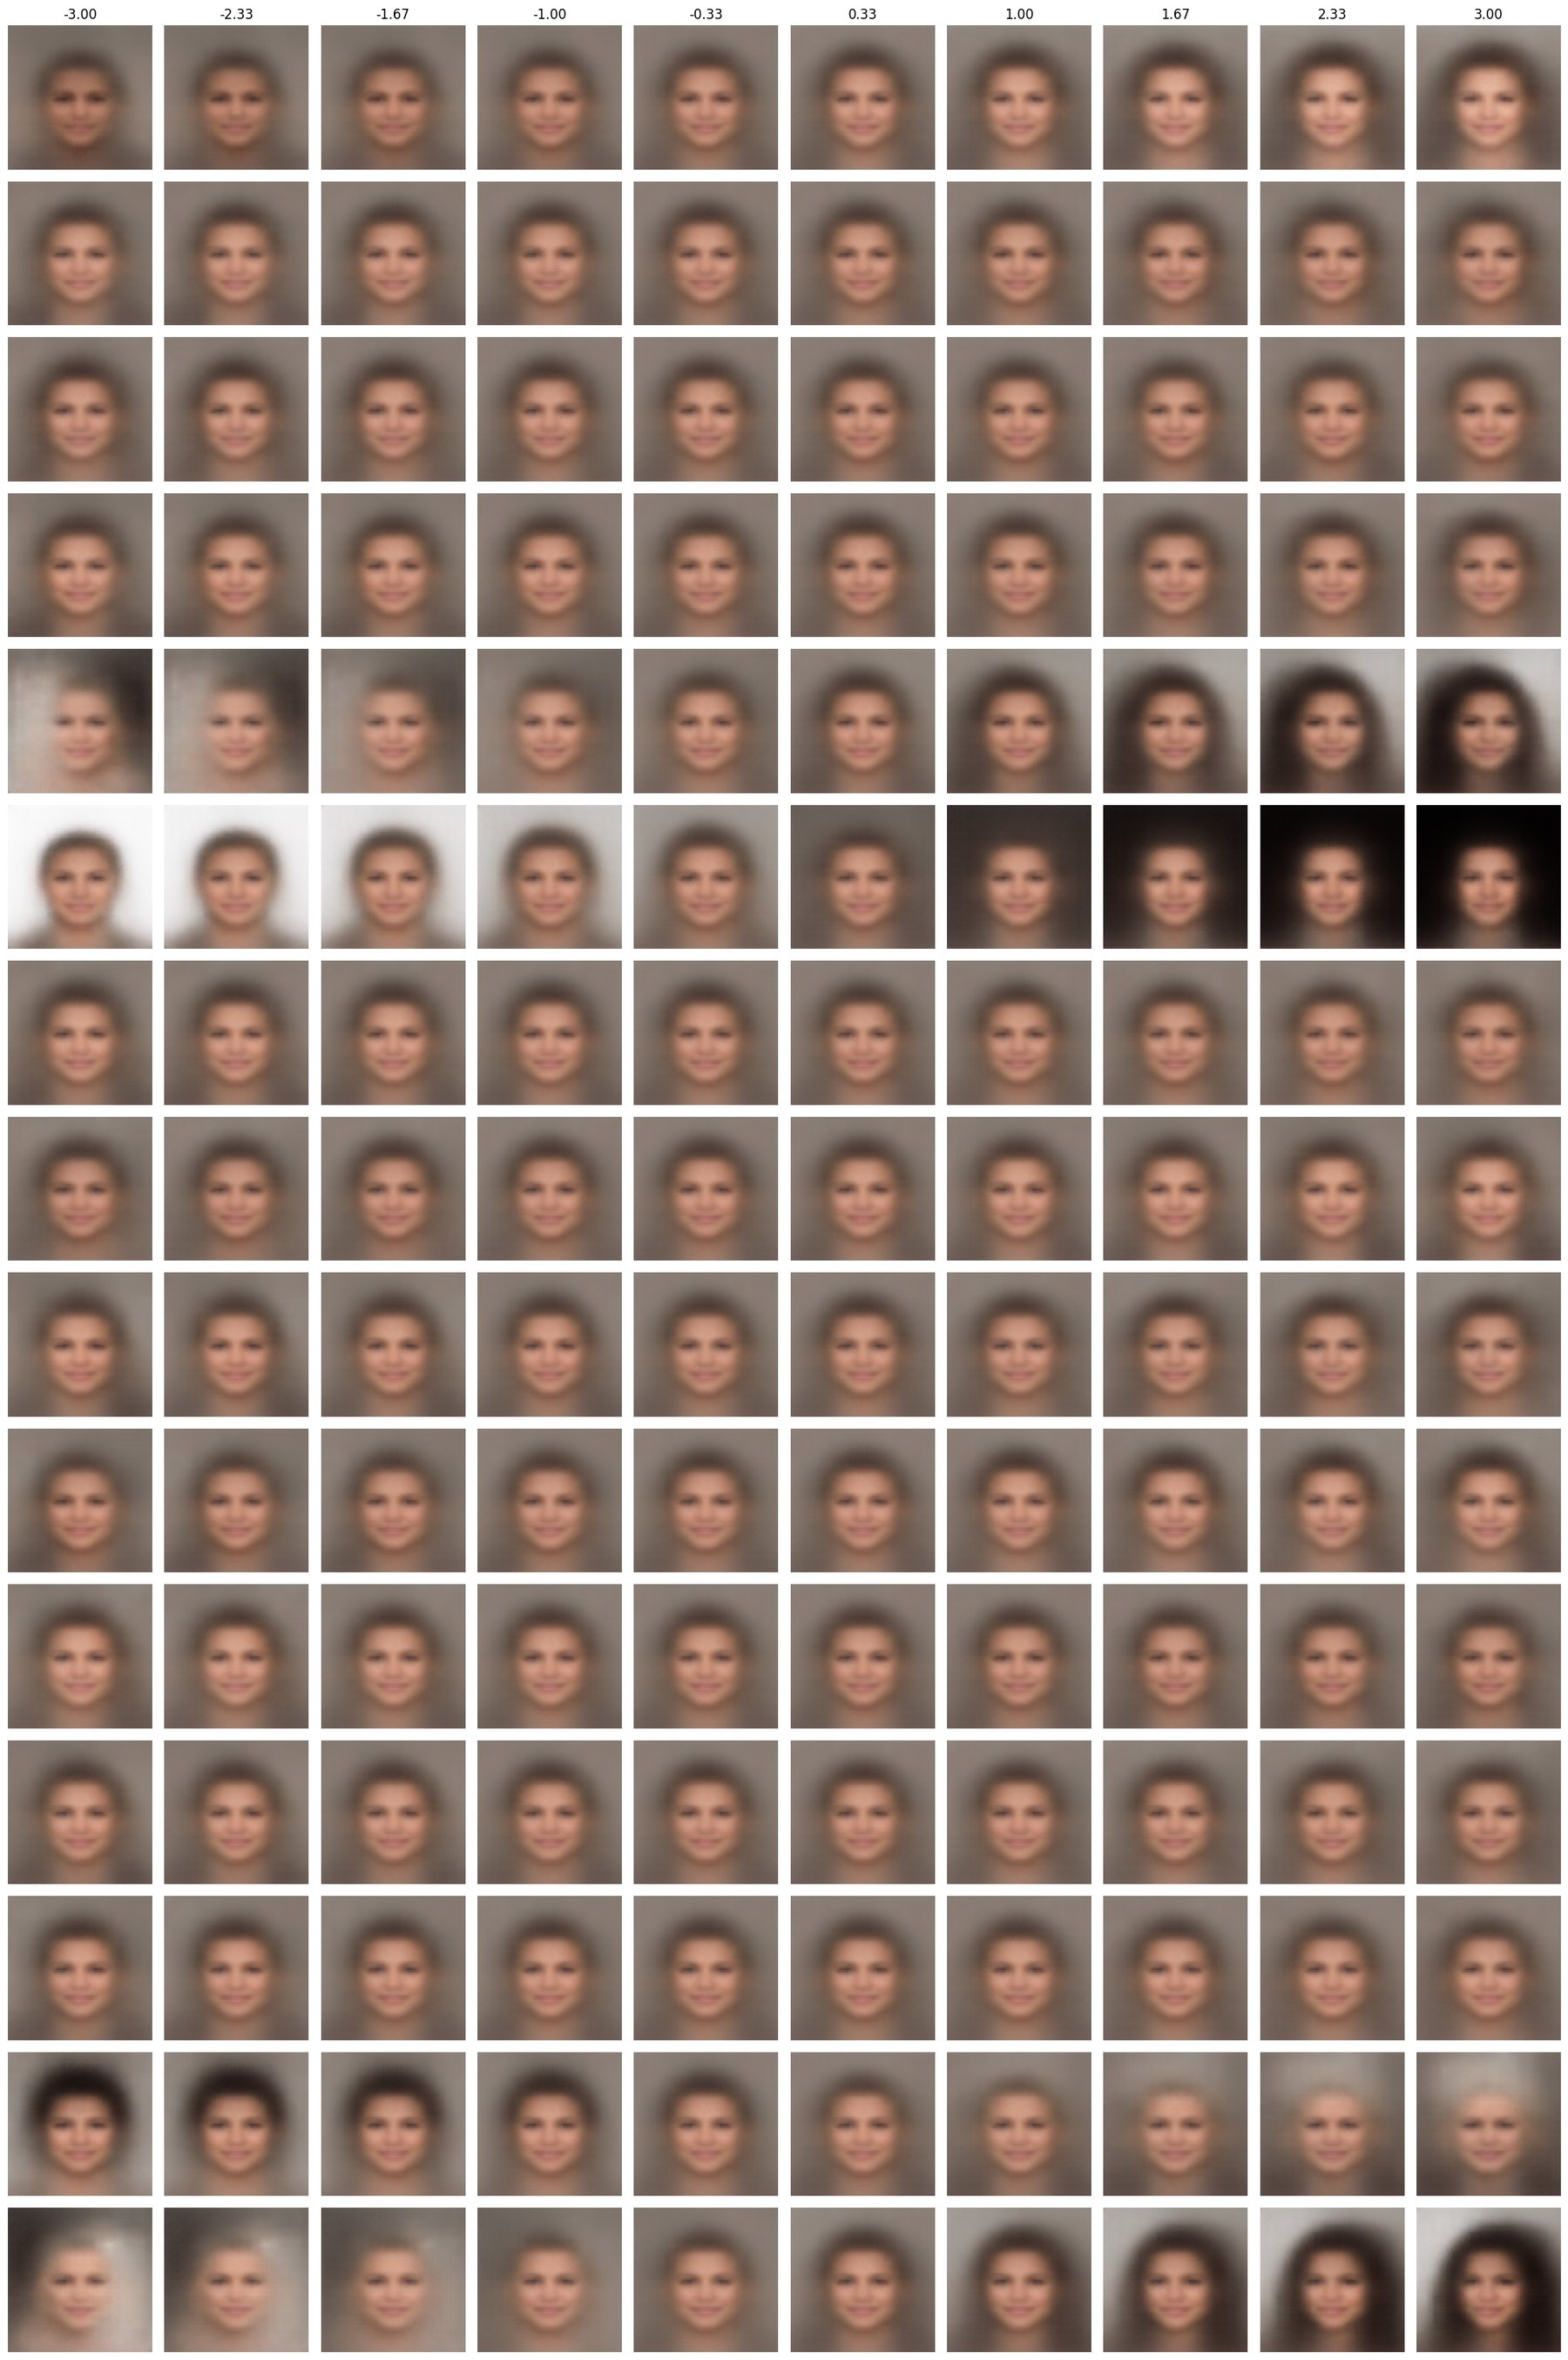

In [17]:
# Code

for beta in BETA_VALUES:
    print(f"Beta = {beta} | Latent Dim = {LATENT_DIM}")
    visualize_disentangled_latent_factors(analysis_models[beta], latent_dim=LATENT_DIM, num_samples=10, variation_range=(-3, 3))

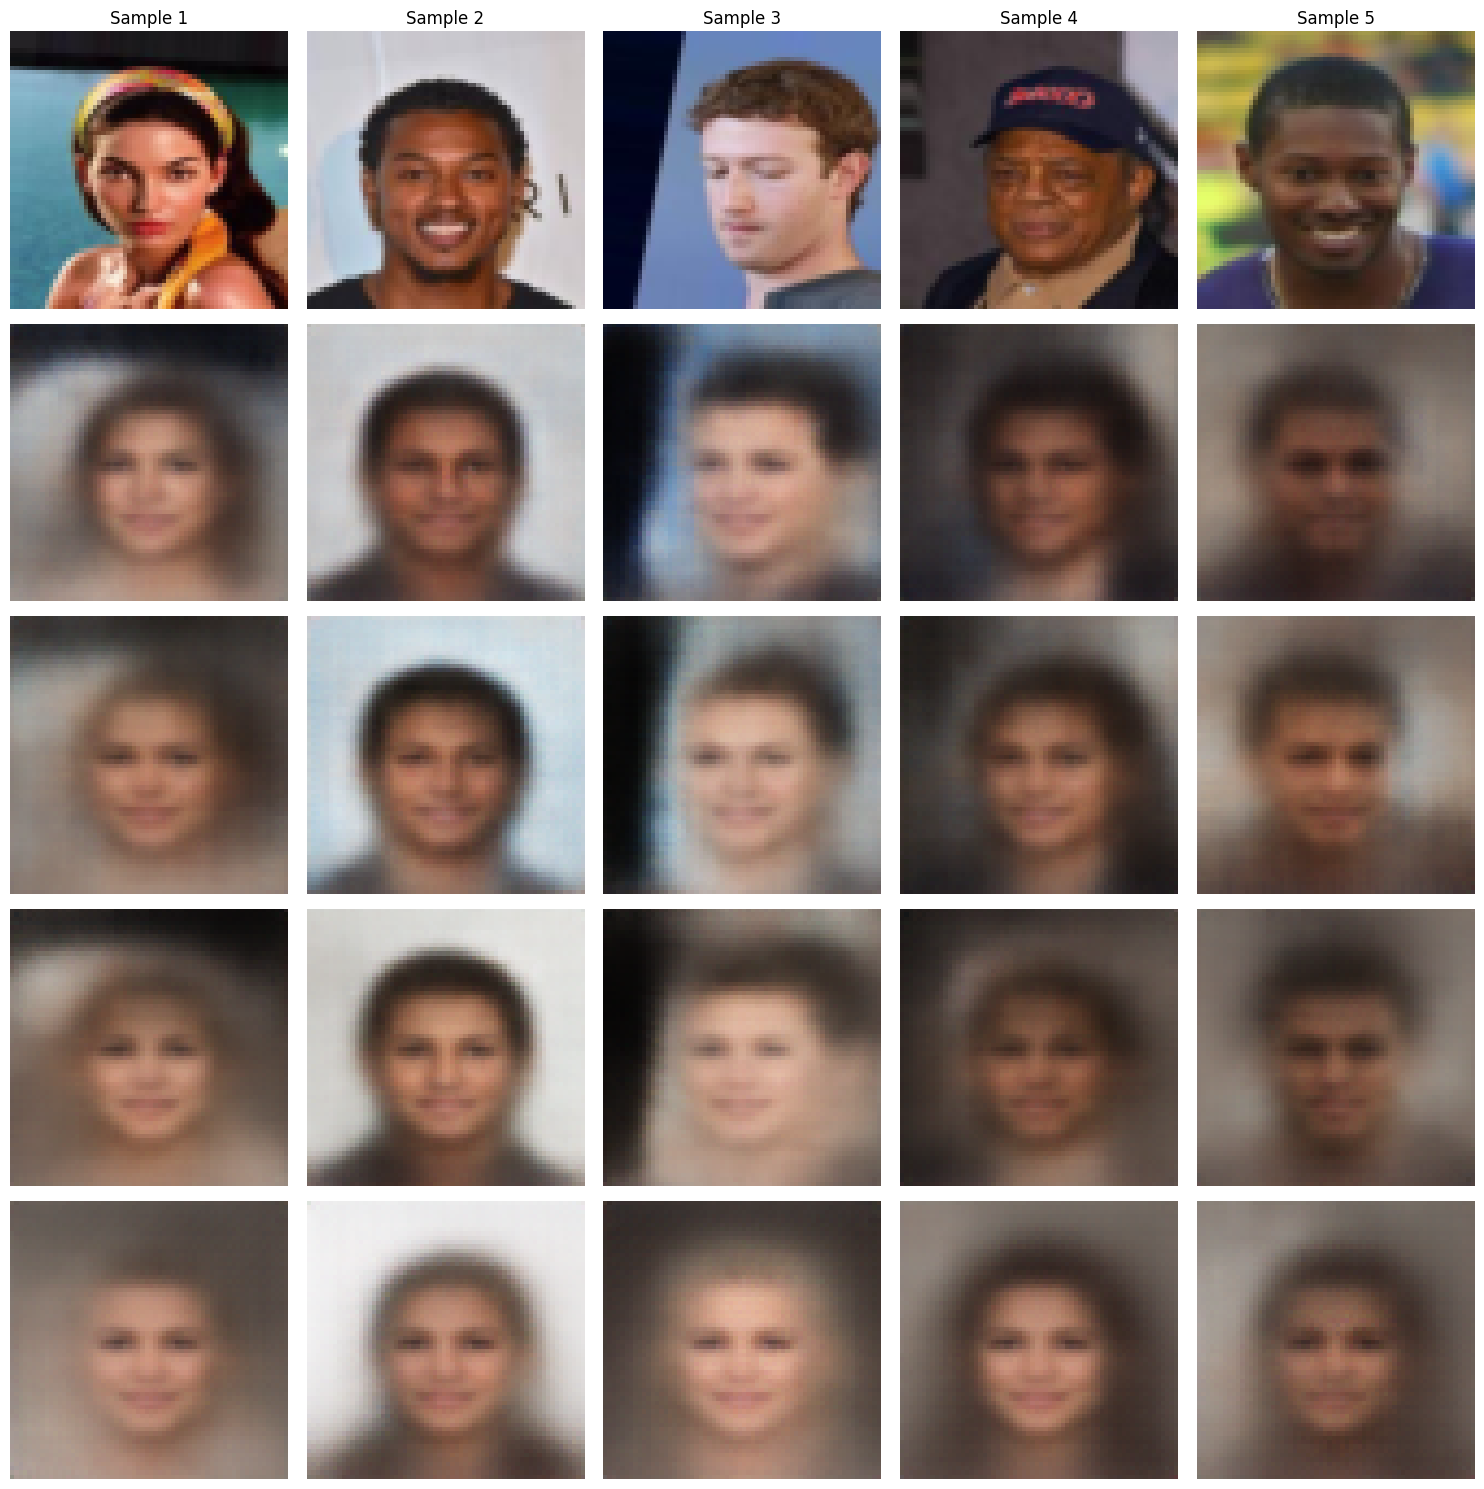

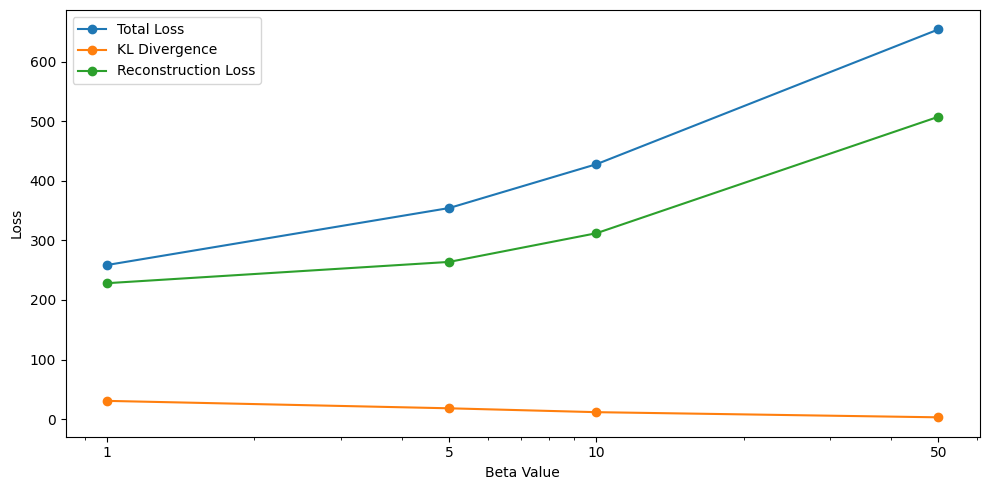

,Beta Value,Latent Dim,Total Loss,KL Divergence,Reconstruction Loss
0,1,15,258.6983,30.5501,228.1481
1,5,15,354.3082,18.0887,263.8649
2,10,15,427.9016,11.5867,312.0348
3,50,15,654.2010,2.9329,507.5577


In [18]:
# Code

sample_images, _, _ = next(iter(test_loader))
sample_images = sample_images[:5].to(device)
fig, axes = plt.subplots(len(BETA_VALUES) + 1, sample_images.size(0), figsize=(sample_images.size(0) * 3, (len(BETA_VALUES) + 1) * 3))
for i in range(sample_images.size(0)):
    axes[0, i].imshow(np.clip(sample_images[i].permute(1, 2, 0).cpu().numpy(), 0, 1))
    axes[0, i].axis("off")
    axes[0, i].set_title(f"Sample {i+1}")
axes[0, 0].set_ylabel("Original")
with torch.no_grad():
    for row, beta in enumerate(BETA_VALUES, start=1):
        recon_x, _, _ = analysis_models[beta](sample_images)
        for col in range(sample_images.size(0)):
            axes[row, col].imshow(np.clip(recon_x[col].permute(1, 2, 0).cpu().numpy(), 0, 1))
            axes[row, col].axis("off")
        axes[row, 0].set_ylabel(f"β={beta}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(results_df["Beta Value"], results_df["Total Loss"], marker="o", label="Total Loss")
plt.plot(results_df["Beta Value"], results_df["KL Divergence"], marker="o", label="KL Divergence")
plt.plot(results_df["Beta Value"], results_df["Reconstruction Loss"], marker="o", label="Reconstruction Loss")
plt.xscale("log")
plt.xticks(BETA_VALUES, BETA_VALUES)
plt.xlabel("Beta Value")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

results_df

<!-- EXPLANATION REQUEST HEADER -->
<div style="width: 100%; text-align: center;">
    <h2 style="color: white; font-size: 30px; font-weight: bold;">
        📝 <b>Please Explain Your Results in Full Detail in the Markdown Below</b> 📝
    </h2>
</div>

<!-- INSTRUCTION BLOCK -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(130, 89, 214, 0.6);">
    
<b>Provide a thorough breakdown of your results.</b>  
Explain every aspect, including:  

- ✅ **Architecture Choice** – Why did you choose this specific architecture?
- ✅ **Observations** – What do the numbers and trends indicate?  
- ✅ **Patterns** – Are there any significant trends in your results?  
- ✅ **Comparison** – How do your findings compare to expected outcomes?  
- ✅ **Errors/Anomalies** – Any unexpected results? Why might they have occurred?  
- ✅ **Insights** – What conclusions can you draw from these results?  

Take your time to articulate **every detail clearly and concisely**.  

</div>


ok

architecture choice = i used a simple convolutional beta-vae with a convolutional encoder, separate mu and logvar layers, reparameterization trick, and a transposed convolution decoder because this architecture is well suited for face images, reduces spatial dimensions in a stable way, keeps the model manageable for colab training, and is strong enough to learn meaningful latent features without becoming unnecessarily heavy for a 3 epoch experiment on celebA...i used a 4 layer conv encoder with channels 3 to 32 to 64 to 128 to 256, two fully connected heads for mu and logvar, and a symmetric 4 layer transposed conv decoder ending with sigmoid, because this gives a compact but expressive architecture that is well suited for 64 by 64 face images and efficient enough to train reliably in colab. in chapter 2 i fixed beta = 5 and experimented with latent dims 5, 10, and 15, and selected latent dim = 15 for chapter 3 because it gave the best validation total loss 355.3273 and the best reconstruction loss 268.0675, compared to 429.5867 and 382.9106 for latent dim 5, and 373.1218 and 305.9065 for latent dim 10. i also varied num_samples and variation range in the latent traversal plots, and this helped make the transitions easier to inspect, with more samples giving smoother intermediate changes and wider ranges making the latent effects look more extreme and noticeable

observations = the numerical results show a very clear tradeoff across beta values, where beta = 1 gives the best reconstruction performance with the lowest reconstruction loss and total loss, while increasing beta to 5, 10, and 50 steadily lowers the kl divergence but increases reconstruction loss, and the graph confirms this exact pattern, while the reconstructions and latent traversals visually show that lower beta preserves image detail better and higher beta produces blurrier but more constrained generations. in chapter 2, increasing latent dim from 5 to 15 at fixed beta = 5 improved the total loss and reconstruction loss noticeably, which suggests that the larger latent space captured more useful facial information for this setup. the chapter 2 traversal experiments also showed that the learned factors became more informative at latent dim 15, while the num_samples experiments mainly changed how smooth and readable the latent transitions looked rather than changing the underlying representation itself

patterns = the most important pattern is that as beta increases, the latent space is forced closer to the prior, so kl divergence drops from 30.5501 at beta = 1 to 2.9329 at beta = 50, but this comes at the cost of image fidelity since reconstruction loss rises from 228.1481 to 507.5577, and the latent factor plots also show that some dimensions increasingly control broad factors like brightness, background darkness, face tone, and coarse hairstyle or shape changes rather than preserving sharp identity details. another clear pattern from chapter 2 is that with beta fixed at 5, moving from latent dim 5 to 10 to 15 reduced the total loss from 429.5867 to 373.1218 to 355.3273 and reduced the reconstruction loss from 382.9106 to 305.9065 to 268.0675, even though kl divergence increased from 9.3352 to 13.4431 to 17.4520. this suggests that in this setup, the extra latent capacity was being used productively rather than just adding noise

comparison = these findings match the expcted behavior of a beta-vae almost perfectly, since standard theory says that lower beta should favor recon quality while higher beta should encourage stronger regularization and better disentanglement, so the results are algned with what is normally expected from this model family. the chapter 2 experiments also make sense relative to theory, because trying multiple latent dims before varying beta is exactly the right way to first identify a reasonable latent capacity, and in my case latent dim 15 clearly worked best, so using that fixed setting for chapter 3 was justified

errors/anomalies = the main anomaly is that many outputs remain blurry and several generations drift toward an average face, but this is not a serious implementation issue and is most likely due to the short training time of only 3 epochs, the relatively small 64 by 64 resolution, the use of mse reconstruction loss, and the natural tendency of vaes to produce smoother images, especially under strong regularization such as beta = 50. another thing i noticed is that even when the latent traversals were interpretable, many rows still changed broad global properties like lighting and skin tone more strongly than very fine semantic details, which means the disentanglement was only partial rather than perfectly clean. the num_samples experiments also showed that changing the number of interpolation points affects readability of the plots, but it does not actually fix the core blur or average face issue, since that mainly comes from the model and training setup itself

insights = overall, the results suggest that beta = 1 is best when the priority is reconstruction quality, beta = 5 or 10 offers a better balance between reconstruction and disentanglement, and beta = 50 over-regularizes the model for this setup, so the final takeaway is that the implementation is correct, the trends are meaningful, and the experiment successfully demonstrates the central beta-vae idea that stronger dissntanglement usually comes by sacrifizing visual sharpness and recon acc. the chapter 2 experiments also gave a useful design insight, which is that latent dim should not just be left at the default blindly, because in my case latent dim 15 was clearly stronger than 5 and 10 at beta = 5 and gave better losses and more useful traversals. overall, the experiments across latent dim, num_samples, variation range, and beta values gave a much fuller picture of how the latent space behaves rather than only showing one fixed setting

<!-- CHAPTER 3 HEADER -->
<div style="text-align: center;">
    <h1 style="color: rgb(255, 165, 0); font-size: 50px; font-weight: bold;">
        🍂 <span style="color: white;">Chapter 4</span> -  
        <span style="color: rgb(255, 165, 0);">Autumn</span> 🍂
        <span style="color: white;">[10 Points]</span>
    </h1>
    <hr style="height: 8px; width: 80%; background: linear-gradient(to right, white, rgb(255, 165, 0), white); border: none; margin-top: 10px; margin-bottom: 10px;">
</div>

<!-- REFLECTION QUESTIONS BLOCK -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.6); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 30px rgba(255, 165, 0, 0.6);">
    
<b>Now that you have reached Autumn, it's time to reflect.</b>  
Answer the following questions thoughtfully:  

## 🔍 Reflection Question 1
### How does increasing β affect disentanglement and reconstruction quality? Please provide a detailed response (Max 100 Words)

Ans: increasing beta strengthens the kl divergence penalty, which pushes the latent space closer to a standard gaussian and usually improves disentanglement by forcing the model to learn more separated and compressed latent factors. in my results, as beta increased from 1 to 50, kl divergence decreased from 30.5501 to 2.9329, showing much stronger regularization. however, this came at the cost of reconstruction quality, as reconstruction loss increased from 228.1481 to 507.5577 and the images became blurrier. so, higher beta improves disentanglement but usually reduces visual fidelity and recon sharpness








## 🔍 Reflection Question 2
### Identify and discuss the limitations of β-VAE, such as loss of fine-grained details in reconstructions or failure to disentangle specific factors. Please provide a detailed response (Max 100 Words)

Ans: it has several limitations. as beta increases, the model often sacrifices fine-grained reconstruction details, so faces become blurrier and more averaged, which was visible in my outputs, especially for beta = 50. another limitation is that disentanglement is not always perfectly clean, since some latent dimensions may mix multiple factors like lighting, pose, and background instead of controlling one clear semantic feature. beta vae is also sensitive to architecture, latent size, training time, and beta selection, so poor choices can lead to over regularization, weak recons, or latent dims that are not very interpretable

<!-- FINAL MISSION HEADER -->
<div style="text-align: center;">
    <h1 style="color: rgb(255, 215, 0); font-size: 55px; font-weight: bold;">
        🎯 <span style="color: white;">Mission Accomplished!</span>  
    </h1>
    <h2 style="color: rgb(255, 140, 0); font-size: 40px; font-weight: bold;">
        <b>The Last of Us: DL Edition Ends Here</b> 🎮🔥
    </h2>
    <hr style="height: 10px; width: 80%; background: linear-gradient(to right, white, rgb(255, 140, 0), white); border: none; margin-top: 10px; margin-bottom: 10px;">
</div>

<!-- STORY CLOSURE -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white; background: rgba(0, 0, 0, 0.7); border-radius: 15px; width: 80%; margin: auto; box-shadow: 0px 0px 40px rgba(255, 140, 0, 0.7);">
<b>A Tale of Vengeance, Survival, and AI</b>

The journey was <b>brutal</b>, the road was <b>long</b>, but <b>Ellie never faltered</b>.
Through <b>blood, sweat, and deep learning</b>, she <b>saw her mission through to the end</b>.

With the power of Variational Autoencoders (VAEs), she uncovered hidden enemies, infiltrating their ranks and exposing those who lurked in the shadows.
The very faction that had <b>taken everything from her</b>—that shattered the last remnants of her world—had now been <b>brought to justice</b>.

💔 <b>For those she lost. For those still fighting.</b> 💔

</div> <!-- SUBHEADING: HOW DID ELLIE USE DL? --> <div style="padding: 10px; text-align: center;"> <h2 style="color: white; font-size: 30px; font-weight: bold;"> 🔬 <b>How Did Ellie Use Deep Learning to Complete Her Mission?</b> </h2> </div> <!-- CINEMATIC STORY BLOCK --> <div style="padding: 30px; text-align: justify; font-size: 22px; color: white; background: rgba(0, 0, 0, 0.7); border-radius: 15px; width: 80%; margin: auto; box-shadow: 0px 0px 40px rgba(255, 140, 0, 0.7);">
🔥 <b>In a world where survival depends on identifying the enemy</b>, Ellie turned to deep learning for answers.

- ✅ Using a β-VAE, she <b>disentangled hidden facial attributes</b> and <b>revealed those who wished to stay hidden</b>.
- ✅ She experimented with different <b>β values</b>, learning how the model traded off between <b>accuracy and interpretability</b>.
- ✅ With enough training, she <b>decoded the WLF's disguises</b>, proving that <b>no mask, no shadow, no camouflage could stop the power of AI</b>.

Her mission was not just about revenge, but about ensuring no one else suffered the same fate.
With the memory of the fallen in her heart and science in her hands, she rewrote fate itself.

⚔️ <b>Justice has been served.</b>
🎮 The Last of Us: AI Edition has come to a close.

🥀 For those we've lost. For those still standing. 🥀

</div>


<!-- MARKING CRITERIA -->
<div style="padding: 10px; text-align: center;">
    <h2 style="color: white; font-size: 35px; font-weight: bold;">
        📜 <b>Marking Criteria & Submission Guidelines</b>  
    </h2>
</div>

<!-- CRITERIA BLOCK -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.7); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 40px rgba(255, 140, 0, 0.7);">

## 📊 **How Will You Be Evaluated?**  

Unlike previous parts of the assignment, there are **no strict benchmarks** (e.g., specific loss values).  
This part is **open-ended**, meaning **multiple correct implementations exist**.  

✅ **We will assess your work based on the following:**  
- **Architecture choices**: How well have you structured your VAE model?  
- **Results**: How effectively does your model learn meaningful latent representations?  
- **Quality of Visualizations**: The true measure of your model's success is in its ability to **clearly separate different features**. Your plots should **demonstrate disentanglement effectively**.  

</div>

<!-- SUBMISSION REQUIREMENTS -->
<div style="padding: 10px; text-align: center;">
    <h2 style="color: white; font-size: 30px; font-weight: bold;">
        📂 <b>Submission Requirements</b>  
    </h2>
</div>

<!-- SUBMISSION INSTRUCTIONS BLOCK -->
<div style="padding: 30px; text-align: justify; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.7); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 40px rgba(255, 140, 0, 0.7);">

### 1️⃣ **Model Checkpoints**  
📌 **Save all 4 trained models** (one for each β value) and upload them to **Dropbox** under your name.  
- **File format**: `.zip`  
- **Naming format**: `<RollNumber>_PA3_1A_Models.zip`  

### 2️⃣ **Notebook Submission**  
📌 Submit **this notebook and its Python file** (`.ipynb` and `.py`) on **LMS** with the rest of the assignment.  

</div>

<!-- FINAL CONGRATULATIONS BLOCK -->
<div style="padding: 30px; font-size: 22px; color: white;
            background: rgba(0, 0, 0, 0.7); border-radius: 15px;
            width: 80%; margin: auto;
            box-shadow: 0px 0px 40px rgba(255, 140, 0, 0.7); text-align: center; font-weight: bold;">
    
🔥 **If you’ve made it this far, congratulations!**  
You’ve successfully implemented a **β-VAE**, explored its impact, and helped Ellie on her quest.  

👑 <b>You are now a true deep learning survivor.</b>  

🚀 **See you in the next adventure!**  

</div>
